In [1]:
%pip -q install openai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\86187\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [3]:
import os, getpass, json, re, time
from dataclasses import dataclass, field
from openai import OpenAI

def _get_openrouter_key():
    k = os.environ.get('MY_PRIVATE_OPENROUTER_KEY') or os.environ.get('OPENROUTER_API_KEY')
    if k: return k
    try:
        from google.colab import userdata
        k = userdata.get('OPENROUTER_API_KEY')
        if k: return k
    except Exception:
        pass
    return getpass.getpass('Paste your OpenRouter API key (hidden): ')

API_KEY = _get_openrouter_key()
client  = OpenAI(base_url='https://openrouter.ai/api/v1', api_key=API_KEY)

GEN_MODEL   = 'openai/gpt-4o-mini'     # the model doing the task
JUDGE_MODEL = 'openai/gpt-4o-mini'     # the model grading it at L2 (see the warning in section 4)
FAST_MODE   = False                    # True -> only the first 5 cases, while you are debugging
TOKENS = {'in': 0, 'out': 0}

def generate(prompt, system=None, model=None, max_new_tokens=350, temperature=0.0):
    """temperature 0 = deterministic. Non-negotiable here: at temperature 1 you cannot tell a
       prompt improvement from sampling luck, and your before/after comparison means nothing."""
    msgs = ([{'role': 'system', 'content': system}] if system else []) + \
           [{'role': 'user', 'content': prompt}]
    r = client.chat.completions.create(model=model or GEN_MODEL, messages=msgs,
                                       temperature=temperature, max_tokens=max_new_tokens)
    if getattr(r, 'usage', None):
        TOKENS['in']  += r.usage.prompt_tokens
        TOKENS['out'] += r.usage.completion_tokens
    return r.choices[0].message.content.strip()

print('connected ·', generate('Reply with exactly the word: ready', max_new_tokens=6))

Paste your OpenRouter API key (hidden):  ········


connected · ready


In [4]:
import urllib.request, json as _json

def credit_check():
    """Ask OpenRouter what is left on your key. Costs nothing."""
    try:
        req = urllib.request.Request('https://openrouter.ai/api/v1/key',
                                     headers={'Authorization': f'Bearer {API_KEY}'})
        d = _json.load(urllib.request.urlopen(req, timeout=20))['data']
        used, cap = d.get('usage'), d.get('limit')
        if cap is None:
            print(f'spent so far: ${used:.4f}   (no cap set on this key)')
        else:
            print(f'spent ${used:.4f} of ${cap:.2f}  ->  ${cap - used:.4f} remaining')
        rl = d.get('rate_limit') or {}
        if rl:
            print(f"rate limit: {rl.get('requests')} requests per {rl.get('interval')}")
    except Exception as e:
        print('could not check credit (not a problem, carry on):', str(e)[:120])

credit_check()

spent $2.1020 of $10.00  ->  $7.8980 remaining
rate limit: -1 requests per 10s


In [8]:
import os
import subprocess

def wsl_bash(script, timeout=900):
    """从 Windows 版 Jupyter 调用 Project3-Ubuntu 里的命令。"""
    env = os.environ.copy()
    env["OPENROUTER_API_KEY"] = API_KEY

    items = [x for x in env.get("WSLENV", "").split(":") if x]
    if not any(x.split("/")[0] == "OPENROUTER_API_KEY" for x in items):
        items.append("OPENROUTER_API_KEY/u")
    env["WSLENV"] = ":".join(items)

    result = subprocess.run(
        ["wsl.exe", "-d", "Project3-Ubuntu", "--", "bash", "-lc", script],
        text=True,
        capture_output=True,
        timeout=timeout,
        env=env,
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"WSL command failed (exit {result.returncode})\n"
            f"STDERR:\n{result.stderr[-4000:]}\n"
            f"STDOUT:\n{result.stdout[-4000:]}"
        )

    return result.stdout

In [11]:
print(
    wsl_bash(
        "env PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin pi --version",
        timeout=30,
    )
)

In [13]:
out = wsl_bash(
    "env PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin pi --version 2>&1; echo CHECK_FINISHED",
    timeout=30,
)
print(repr(out))

'0.73.1\nCHECK_FINISHED\n'


In [9]:
import os
import subprocess

def wsl_bash(script, timeout=900):
    """从 Windows Jupyter 安全地把多行脚本送进 Project3-Ubuntu。"""
    env = os.environ.copy()
    env["OPENROUTER_API_KEY"] = API_KEY

    items = [x for x in env.get("WSLENV", "").split(":") if x]
    if not any(x.split("/")[0] == "OPENROUTER_API_KEY" for x in items):
        items.append("OPENROUTER_API_KEY/u")
    env["WSLENV"] = ":".join(items)

    clean_script = script.replace("\r\n", "\n").replace("\r", "\n")

    result = subprocess.run(
        ["wsl.exe", "-d", "Project3-Ubuntu", "--", "bash", "-s"],
        input=clean_script.encode("utf-8"),
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        timeout=timeout,
        env=env,
    )

    stdout = result.stdout.decode("utf-8", errors="replace")
    stderr = result.stderr.decode("utf-8", errors="replace")

    if result.returncode != 0:
        raise RuntimeError(
            f"WSL command failed (exit {result.returncode})\n"
            f"STDERR:\n{stderr[-4000:]}\n"
            f"STDOUT:\n{stdout[-4000:]}"
        )

    return stdout

In [21]:
check_script = r"""
SAFE_PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

echo "=== PI Agent ==="
env PATH="$SAFE_PATH" pi --version 2>&1 || true

echo
echo "=== Docker ==="
env PATH="$SAFE_PATH" docker version --format '{{.Server.Version}}' 2>&1 || true

echo
echo "=== SkillsBench paper-anonymizer ==="
TASK=/opt/project3/skillsbench-tasks/paper-anonymizer/task.yaml

if [ -f "$TASK" ]; then
    echo "FOUND: $TASK"
    echo
    echo "--- task.yaml preview ---"
    sed -n '1,25p' "$TASK"
else
    echo "NOT FOUND: $TASK"
fi
"""

print(wsl_bash(check_script, timeout=60))

=== PI Agent ===
0.73.1

=== Docker ===
29.9.2

=== SkillsBench paper-anonymizer ===
NOT FOUND: /opt/project3/skillsbench-tasks/paper-anonymizer/task.yaml



In [22]:
search_script = r"""
echo "Searching known SkillsBench folders..."

for ROOT in \
  /opt/project3/skillsbench-tasks \
  /mnt/d/Downloads/skillsbench_v1.1_source \
  /mnt/d/Downloads/skillsbench-1.1
do
  if [ -d "$ROOT" ]; then
    echo
    echo "--- Searching: $ROOT ---"
    find "$ROOT" -type f -path "*/paper-anonymizer/task.yaml" -print 2>/dev/null
  fi
done
"""

print(wsl_bash(search_script, timeout=60))

Searching known SkillsBench folders...

--- Searching: /opt/project3/skillsbench-tasks ---

--- Searching: /mnt/d/Downloads/skillsbench_v1.1_source ---



In [23]:
SKILLSBENCH_ROOT = "/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1"
TASK_NAME = "paper-anonymizer"
TASK_DIR = f"{SKILLSBENCH_ROOT}/tasks/{TASK_NAME}"
ENV_DIR = f"{TASK_DIR}/environment"

preview_script = f"""
set -eu

echo "=== Task folder ==="
ls -la "{TASK_DIR}"

echo
echo "=== Task brief ==="
sed -n '1,220p' "{TASK_DIR}/task.md"

echo
echo "=== Dockerfile ==="
sed -n '1,160p' "{ENV_DIR}/Dockerfile"

echo
echo "=== Verifier files ==="
find "{TASK_DIR}/verifier" -maxdepth 1 -type f -printf '%f\\n' | sort
"""

print(wsl_bash(preview_script, timeout=60))

=== Task folder ===
total 4
drwxrwxrwx 1 root root 4096 Oct 27 14:56 .
drwxrwxrwx 1 root root 4096 Oct 27 14:56 ..
drwxrwxrwx 1 root root 4096 Oct 27 14:56 environment
drwxrwxrwx 1 root root 4096 Oct 27 14:56 oracle
-rwxrwxrwx 1 root root 1363 Jun 16 15:10 task.md
drwxrwxrwx 1 root root 4096 Oct 27 14:56 verifier

=== Task brief ===
---
schema_version: '1.3'
metadata:
  author_name: Yueqian Lin
  author_email: yl768@duke.edu
  difficulty: medium
  category: office-white-collar
  subcategory: document-editing
  category_confidence: high
  secondary_category: media-content-production
  task_type:
  - transformation
  - detection
  modality:
  - pdf
  interface:
  - terminal
  - python
  skill_type:
  - file-format-knowledge
  - domain-procedure
  tags:
  - pdf
  - redaction
  - anonymization
  - blind-review
verifier:
  type: test-script
  timeout_sec: 300.0
  service: main
  hardening:
    cleanup_conftests: true
agent:
  timeout_sec: 1000.0
environment:
  network_mode: public
  build_t

In [24]:
catalog_script = f"""
set -eu
ROOT="{SKILLSBENCH_ROOT}/tasks"

printf "%-38s %-10s %s\\n" "TASK" "DIFFICULTY" "CATEGORY"
printf "%-38s %-10s %s\\n" "----" "----------" "--------"

for TASK_MD in "$ROOT"/*/task.md; do
    NAME=$(basename "$(dirname "$TASK_MD")")
    DIFFICULTY=$(awk '/^  difficulty:/ {{print $2; exit}}' "$TASK_MD")
    CATEGORY=$(awk '/^  category:/ {{print $2; exit}}' "$TASK_MD")
    printf "%-38s %-10s %s\\n" "$NAME" "${{DIFFICULTY:-unknown}}" "${{CATEGORY:-unknown}}"
done | sort
"""

print(wsl_bash(catalog_script, timeout=60))

TASK                                   DIFFICULTY CATEGORY
----                                   ---------- --------
3d-scan-calc                           hard       industrial-physical-systems
ada-bathroom-plan-repair               hard       industrial-physical-systems
adaptive-cruise-control                medium     industrial-physical-systems
azure-bgp-oscillation-route-leak       medium     software-engineering
bike-rebalance                         medium     mathematics-or-formal-reasoning
citation-check                         medium     office-white-collar
civ6-adjacency-optimizer               hard       mathematics-or-formal-reasoning
court-form-filling                     easy       office-white-collar
crystallographic-wyckoff-position-analysis medium     natural-science
dapt-intrusion-detection               hard       cybersecurity
data-to-d3                             medium     software-engineering
debug-trl-grpo                         hard       software-engineeri

In [25]:
pi_help_script = r"""
SAFE_PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

env PATH="$SAFE_PATH" pi --help 2>&1 | sed -n '1,220p'
"""

print(wsl_bash(pi_help_script, timeout=60))

pi - AI coding assistant with read, bash, edit, write tools

Usage:
  pi [options] [@files...] [messages...]

Commands:
  pi install <source> [-l]     Install extension source and add to settings
  pi remove <source> [-l]      Remove extension source from settings
  pi uninstall <source> [-l]   Alias for remove
  pi update [source|self|pi]   Update pi and installed extensions
  pi list                      List installed extensions from settings
  pi config                    Open TUI to enable/disable package resources
  pi <command> --help          Show help for install/remove/uninstall/update/list

Options:
  --provider <name>              Provider name (default: google)
  --model <pattern>              Model pattern or ID (supports "provider/id" and optional ":<thinking>")
  --api-key <key>                API key (defaults to env vars)
  --system-prompt <text>         System prompt (default: coding assistant prompt)
  --append-system-prompt <text>  Append text or file contents to t

In [26]:
import json

PROVIDER = "openrouter"
MODEL = "openai/gpt-4o-mini"
TOTAL_BUDGET_USD = 9.00

VALIDATION_TASKS = [
    "dialogue-parser",
    "paper-anonymizer",
]

TEST_TASKS = [
    "offer-letter-generator",
    "court-form-filling",
]

DEFAULT_CONFIG = {
    "label": "default",
    "thinking": "off",
    "tool_profile": "default",
    "append_system_prompt": None,
}

SEARCH_SPACE = {
    "thinking": ["off", "minimal", "low", "medium"],
    "tool_profile": {
        "default": None,
        "full": "read,bash,edit,write,grep,find,ls",
    },
    "prompt_style": {
        "default": None,
        "verify": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
}

EXPERIMENT_PROTOCOL = {
    "harness": "PI Agent 0.73.1",
    "benchmark": "SkillsBench 1.1",
    "model": MODEL,
    "validation_tasks": VALIDATION_TASKS,
    "test_tasks": TEST_TASKS,
    "methods": [
        "default",
        "random_search",
        "bayesian_optimization",
        "custom_cost_aware_search",
    ],
    "total_budget_usd": TOTAL_BUDGET_USD,
    "rule": (
        "Use validation only to select a configuration. "
        "Run held-out test tasks only after the configuration is frozen."
    ),
}

print(json.dumps(EXPERIMENT_PROTOCOL, indent=2, ensure_ascii=False))
print("\nDefault configuration:")
print(json.dumps(DEFAULT_CONFIG, indent=2, ensure_ascii=False))

{
  "harness": "PI Agent 0.73.1",
  "benchmark": "SkillsBench 1.1",
  "model": "openai/gpt-4o-mini",
  "validation_tasks": [
    "dialogue-parser",
    "paper-anonymizer"
  ],
  "test_tasks": [
    "offer-letter-generator",
    "court-form-filling"
  ],
  "methods": [
    "default",
    "random_search",
    "bayesian_optimization",
    "custom_cost_aware_search"
  ],
  "total_budget_usd": 9.0,
  "rule": "Use validation only to select a configuration. Run held-out test tasks only after the configuration is frozen."
}

Default configuration:
{
  "label": "default",
  "thinking": "off",
  "tool_profile": "default",
  "append_system_prompt": null
}


In [27]:
docker_inventory_script = r"""
SAFE_PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

echo "=== Existing task-related Docker images ==="
env PATH="$SAFE_PATH" docker images --format '{{.Repository}}\t{{.Tag}}\t{{.Size}}' \
  | grep -Ei 'paper|skillsbench|dialogue|offer|court' || true

echo
echo "=== Existing containers (read only) ==="
env PATH="$SAFE_PATH" docker ps -a --format 'table {{.Names}}\t{{.Image}}\t{{.Status}}' || true

echo
echo "=== Docker disk usage ==="
env PATH="$SAFE_PATH" docker system df || true
"""

print(wsl_bash(docker_inventory_script, timeout=60))

=== Existing task-related Docker images ===
paper-anonymizer__87b676f4-main	latest	1.1GB

=== Existing containers (read only) ===
NAMES     IMAGE     STATUS

=== Docker disk usage ===
TYPE            TOTAL     ACTIVE    SIZE      RECLAIMABLE
Images          1         0         1.096GB   1.096GB (99%)
Containers      0         0         0B        0B
Local Volumes   0         0         0B        0B
Build Cache     8         0         1.104GB   1.104GB



In [28]:
bench_help_script = r"""
SAFE_PATH=/opt/project3/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

env PATH="$SAFE_PATH" bench eval run --help 2>&1 | sed -n '1,260p'
"""

print(wsl_bash(bench_help_script, timeout=60))

                                                                                
 Usage: bench eval run [OPTIONS]                                                
                                                                                
 Run an evaluation — single task or batch.                                      
                                                                                
 Sandbox: docker, daytona, or modal.                                            
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --config                               <path>   YAML config file             │
│ --tasks-dir                            <path>   Local tasks directory        │
│ --source-repo                          <str>    Remote repo as org/repo      │
│                                                 (e.g.                        │
│                           

In [29]:
pi_in_docker_check = r"""
SAFE_PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
IMAGE=paper-anonymizer__87b676f4-main:latest
PI_ROOT=/opt/project3/pi-direct

echo "Starting temporary container check..."
env PATH="$SAFE_PATH" docker run --rm \
  -v "$PI_ROOT:$PI_ROOT:ro" \
  "$IMAGE" \
  bash -lc '
    export PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
    pi --version 2>&1
  '

echo "PI_DOCKER_CHECK_FINISHED"
"""

print(wsl_bash(pi_in_docker_check, timeout=60))

Starting temporary container check...
0.73.1
PI_DOCKER_CHECK_FINISHED



In [31]:
oracle_check_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{TASK_DIR}"
IMAGE="paper-anonymizer__87b676f4-main:latest"
CONTAINER="oracle-paper-anonymizer-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Run official Oracle solution ==="
docker cp "$TASK_DIR/oracle/solve.sh" "$CONTAINER:/oracle_solve.sh"
docker exec "$CONTAINER" bash /oracle_solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_check_script, timeout=180))

=== Create temporary Oracle container ===
=== Run official Oracle solution ===
Redacted /root/paper1.pdf -> /root/redacted/paper1.pdf
Redacted /root/paper2.pdf -> /root/redacted/paper2.pdf
Redacted /root/paper3.pdf -> /root/redacted/paper3.pdf
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.4.1, pluggy-1.7.0 -- /root/.cache/uv/archive-v0/OLcyTTquRdEXTHvME3jcg/bin/python
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.5
collecting ... collected 6 items

../verifier/test_outputs.py::test_structural_integrity PASSED            [ 16%]
../verifier/test_outputs.py::test_authors_redacted PASSED                [ 33%]
../verifier/test_outputs.py::test_affiliations_redacted PASSED           [ 50%]
../verifier/test_outputs.py::test_identifiers_redacted PASSED            [ 66%]
../verifier/test_outputs.py::test_content_preserved PASSED               [ 83%]
../verifier/test_out

In [10]:
import base64
import json
import re
import shlex
import time
import uuid
from pathlib import Path
import urllib.request

# 结果会保存到当前 notebook 同级目录；也就是你的 D 盘作业文件夹中。
RUNS_DIR = Path.cwd() / "project3_pi_hpo_runs"
RUNS_DIR.mkdir(exist_ok=True)

# 目前已存在的镜像。其他三题的镜像之后再构建。
TASK_IMAGES = {
    "paper-anonymizer": "paper-anonymizer__87b676f4-main:latest",
}

def openrouter_credit_snapshot():
    """读取余额/累计使用额；不会调用模型。"""
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/key",
        headers={"Authorization": f"Bearer {API_KEY}"},
    )
    data = json.load(urllib.request.urlopen(req, timeout=20))["data"]
    return {
        "used_usd": float(data.get("usage") or 0.0),
        "limit_usd": float(data.get("limit") or TOTAL_BUDGET_USD),
    }

def windows_to_wsl_path(path):
    """把 D:\\... 路径转换为 WSL 可访问的 /mnt/d/... 路径。"""
    command = "PATH=/usr/bin:/bin wslpath -a " + shlex.quote(str(path))
    return wsl_bash(command, timeout=30).strip()

RUNS_DIR_WSL = windows_to_wsl_path(RUNS_DIR)

def resolve_pi_config(config):
    """把 notebook 中的简短配置转成 PI 命令行参数。"""
    tool_profile = config.get("tool_profile", "default")
    tools = SEARCH_SPACE["tool_profile"][tool_profile]

    append_prompt = config.get("append_system_prompt")
    if append_prompt is None and "prompt_style" in config:
        append_prompt = SEARCH_SPACE["prompt_style"][config["prompt_style"]]

    return {
        "label": config.get("label", "unnamed"),
        "thinking": config.get("thinking", "off"),
        "tools": tools or "",
        "append_system_prompt": append_prompt or "",
    }

def run_pi_task(task_name, config, wall_seconds=360):
    """
    在 SkillsBench Docker 容器内运行一次 PI，并保存：
    - PI 输出日志
    - 官方 verifier 输出
    - pass/fail、耗时和 OpenRouter 美元成本
    """
    if task_name not in TASK_IMAGES:
        raise ValueError(
            f"{task_name} 的 Docker 镜像尚未构建。当前可运行：{list(TASK_IMAGES)}"
        )

    pi_config = resolve_pi_config(config)
    run_id = f"{task_name}-{pi_config['label']}-{uuid.uuid4().hex[:8]}"
    run_dir = RUNS_DIR / run_id
    run_dir.mkdir()

    task_dir = f"{SKILLSBENCH_ROOT}/tasks/{task_name}"
    image = TASK_IMAGES[task_name]
    user_prompt = (
        "Read /task.md and complete the task inside this container. "
        "Use the available tools and create every required output file. "
        "Do not merely explain the solution; perform the work."
    )

    def b64(value):
        return base64.b64encode(value.encode("utf-8")).decode("ascii")

    values = {
        "__TASK_DIR_B64__": b64(task_dir),
        "__IMAGE_B64__": b64(image),
        "__RUN_ID_B64__": b64(run_id),
        "__OUT_DIR_B64__": b64(windows_to_wsl_path(run_dir)),
        "__THINKING_B64__": b64(pi_config["thinking"]),
        "__TOOLS_B64__": b64(pi_config["tools"]),
        "__APPEND_B64__": b64(pi_config["append_system_prompt"]),
        "__PROMPT_B64__": b64(user_prompt),
        "__WALL_SECONDS__": str(wall_seconds),
    }

    shell_script = r"""
set -u
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
PI_ROOT=/opt/project3/pi-direct

decode() { printf '%s' "$1" | base64 -d; }

TASK_DIR=$(decode "__TASK_DIR_B64__")
IMAGE=$(decode "__IMAGE_B64__")
RUN_ID=$(decode "__RUN_ID_B64__")
OUT_DIR=$(decode "__OUT_DIR_B64__")
THINKING=$(decode "__THINKING_B64__")
TOOLS=$(decode "__TOOLS_B64__")
APPEND_PROMPT=$(decode "__APPEND_B64__")
TASK_PROMPT=$(decode "__PROMPT_B64__")
WALL_SECONDS=__WALL_SECONDS__

CONTAINER="pi-run-${RUN_ID}"

cleanup() {
  docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}
trap cleanup EXIT

mkdir -p "$OUT_DIR"

MOUNTS=(
  -v "$PI_ROOT:$PI_ROOT:ro"
  -v "$TASK_DIR/task.md:/task.md:ro"
)

if [ -d "$TASK_DIR/environment/skills" ]; then
  MOUNTS+=(-v "$TASK_DIR/environment/skills:/root/.agents/skills:ro")
fi

echo "Creating task container: $CONTAINER"
docker run -d --name "$CONTAINER" "${MOUNTS[@]}" "$IMAGE" sleep infinity >/dev/null

echo "Running PI (wall cap: ${WALL_SECONDS}s)"
set +e
timeout "$WALL_SECONDS" docker exec -i \
  -e OPENROUTER_API_KEY \
  -e PI_CODING_AGENT_DIR=/tmp/pi-agent \
  -e RUN_THINKING="$THINKING" \
  -e RUN_TOOLS="$TOOLS" \
  -e RUN_APPEND_PROMPT="$APPEND_PROMPT" \
  -e RUN_PROMPT="$TASK_PROMPT" \
  "$CONTAINER" bash -s <<'INNER' > "$OUT_DIR/pi_output.txt" 2>&1
export PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

ARGS=(--provider openrouter --model openai/gpt-4o-mini --print --no-session --thinking "$RUN_THINKING")

if [ -n "$RUN_TOOLS" ]; then
  ARGS+=(--tools "$RUN_TOOLS")
fi

if [ -n "$RUN_APPEND_PROMPT" ]; then
  ARGS+=(--append-system-prompt "$RUN_APPEND_PROMPT")
fi

pi "${ARGS[@]}" "$RUN_PROMPT"
INNER
PI_EXIT=$?
set -e

docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier" >/dev/null

set +e
docker exec "$CONTAINER" bash /verifier/test.sh > "$OUT_DIR/verifier_output.txt" 2>&1
VERIFIER_EXIT=$?
set -e

printf '{"run_id":"%s","pi_exit":%s,"verifier_exit":%s}\n' \
  "$RUN_ID" "$PI_EXIT" "$VERIFIER_EXIT" > "$OUT_DIR/container_result.json"

echo "__RUN_STATUS__ pi_exit=${PI_EXIT} verifier_exit=${VERIFIER_EXIT} output_dir=${OUT_DIR}"
"""

    for marker, value in values.items():
        shell_script = shell_script.replace(marker, value)

    before = openrouter_credit_snapshot()
    started = time.time()
    terminal_log = wsl_bash(shell_script, timeout=wall_seconds + 120)
    elapsed_seconds = round(time.time() - started, 2)
    after = openrouter_credit_snapshot()

    match = re.search(r"pi_exit=(\d+)\s+verifier_exit=(\d+)", terminal_log)
    pi_exit = int(match.group(1)) if match else None
    verifier_exit = int(match.group(2)) if match else None

    result = {
        "run_id": run_id,
        "task": task_name,
        "config": pi_config,
        "pass_at_1": int(verifier_exit == 0),
        "pi_exit": pi_exit,
        "verifier_exit": verifier_exit,
        "elapsed_seconds": elapsed_seconds,
        "cost_usd": round(after["used_usd"] - before["used_usd"], 6),
        "credit_before_usd": before,
        "credit_after_usd": after,
        "run_directory": str(run_dir),
    }

    (run_dir / "summary.json").write_text(
        json.dumps(result, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print(json.dumps(result, ensure_ascii=False, indent=2))
    print("\nTerminal summary:")
    print(terminal_log[-1500:])
    return result

print(f"Runner ready. Results will be saved in:\n{RUNS_DIR}")

Runner ready. Results will be saved in:
C:\Users\86187\project3_pi_hpo_runs


In [34]:
DEFAULT_PAPER_RESULT = run_pi_task(
    task_name="paper-anonymizer",
    config=DEFAULT_CONFIG,
    wall_seconds=240,
)

{
  "run_id": "paper-anonymizer-default-fdc002b6",
  "task": "paper-anonymizer",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 31.41,
  "cost_usd": 0.0,
  "credit_before_usd": {
    "used_usd": 0.08640765,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.08640765,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-default-fdc002b6"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-default-fdc002b6
Running PI (wall cap: 240s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/paper-anonymizer-default-fdc002b6



In [35]:
build_dialogue_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK="dialogue-parser"
TASK_DIR="{SKILLSBENCH_ROOT}/tasks/$TASK"
IMAGE="dialogue-parser-local:latest"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_dialogue_script, timeout=600))

TASK_IMAGES["dialogue-parser"] = "dialogue-parser-local:latest"
print("\nRegistered dialogue-parser in TASK_IMAGES.")

=== Building dialogue-parser-local:latest ===

=== Image ready ===
dialogue-parser-local:latest  369MB


Registered dialogue-parser in TASK_IMAGES.


In [37]:
oracle_dialogue_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{SKILLSBENCH_ROOT}/tasks/dialogue-parser"
IMAGE="dialogue-parser-local:latest"
CONTAINER="oracle-dialogue-parser-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Copy official Oracle and task skill ==="
docker cp "$TASK_DIR/oracle" "$CONTAINER:/oracle"
docker cp "$TASK_DIR/environment/skills" "$CONTAINER:/skills"

echo "=== Run official Oracle solution ==="
docker exec "$CONTAINER" bash /oracle/solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_dialogue_script, timeout=180))

=== Create temporary Oracle container ===
=== Copy official Oracle and task skill ===
=== Run official Oracle solution ===
Generated /app/dialogue.json with 204 nodes and 321 edges
Solution completed. Checking output...
-rw-r--r-- 1 root root 62985 Oct 27 13:07 dialogue.json
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.8, pytest-8.3.4, pluggy-1.7.0 -- /usr/local/bin/python3.12
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.6
collecting ... collected 35 items

../verifier/test_outputs.py::test_system_basics[json_structure] PASSED   [  2%]
../verifier/test_outputs.py::test_system_basics[schema_validation] PASSED [  5%]
../verifier/test_outputs.py::test_system_basics[dot_exists] PASSED       [  8%]
../verifier/test_outputs.py::test_system_basics[graph_size] PASSED       [ 11%]
../verifier/test_outputs.py::test_narrative_content[speaker-Narrator] PASSED [ 14%]
../verifier/test

In [38]:
DEFAULT_DIALOGUE_RESULT = run_pi_task(
    task_name="dialogue-parser",
    config=DEFAULT_CONFIG,
    wall_seconds=240,
)

{
  "run_id": "dialogue-parser-default-130db9f6",
  "task": "dialogue-parser",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 82.55,
  "cost_usd": 0.017808,
  "credit_before_usd": {
    "used_usd": 0.1060329,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.12384075,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\dialogue-parser-default-130db9f6"
}

Terminal summary:
Creating task container: pi-run-dialogue-parser-default-130db9f6
Running PI (wall cap: 240s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/dialogue-parser-default-130db9f6



In [39]:
# 1) 修正 paper-anonymizer 的延迟结算成本
paper_summary_path = (
    RUNS_DIR / "paper-anonymizer-default-fdc002b6" / "summary.json"
)

paper_summary = json.loads(
    paper_summary_path.read_text(encoding="utf-8")
)

paper_cost_reconciled = round(
    DEFAULT_DIALOGUE_RESULT["credit_before_usd"]["used_usd"]
    - paper_summary["credit_before_usd"]["used_usd"],
    6,
)

paper_summary["cost_usd_raw_immediate"] = paper_summary["cost_usd"]
paper_summary["cost_usd"] = paper_cost_reconciled
paper_summary["cost_status"] = (
    "reconciled from the next run's pre-run OpenRouter usage snapshot; "
    "the provider usage endpoint settled after the first run ended"
)
paper_summary["credit_settled_before_next_run_usd"] = (
    DEFAULT_DIALOGUE_RESULT["credit_before_usd"]["used_usd"]
)

paper_summary_path.write_text(
    json.dumps(paper_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 2) 把已运行的简单题标为 pilot；正式 validation 换为一易一难
PILOT_TASKS = ["dialogue-parser"]
VALIDATION_TASKS = ["paper-anonymizer", "edit-pdf"]

EXPERIMENT_PROTOCOL["pilot_calibration_task"] = PILOT_TASKS
EXPERIMENT_PROTOCOL["validation_tasks"] = VALIDATION_TASKS
EXPERIMENT_PROTOCOL["scope_amendment"] = (
    "Before any held-out test run, dialogue-parser was reclassified as a "
    "pilot calibration task because the default configuration reached the "
    "validation ceiling. edit-pdf was added as a more discriminative "
    "validation task. The test split remains untouched."
)

print(f"Corrected paper-anonymizer cost: ${paper_cost_reconciled:.6f}")
print(f"Known baseline cost total: ${paper_cost_reconciled + DEFAULT_DIALOGUE_RESULT['cost_usd']:.6f}")
print("Final validation tasks:", VALIDATION_TASKS)
print("Held-out test tasks (untouched):", TEST_TASKS)

Corrected paper-anonymizer cost: $0.019625
Known baseline cost total: $0.037433
Final validation tasks: ['paper-anonymizer', 'edit-pdf']
Held-out test tasks (untouched): ['offer-letter-generator', 'court-form-filling']


In [40]:
build_edit_pdf_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK="edit-pdf"
TASK_DIR="{SKILLSBENCH_ROOT}/tasks/$TASK"
IMAGE="edit-pdf-local:latest"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_edit_pdf_script, timeout=600))

TASK_IMAGES["edit-pdf"] = "edit-pdf-local:latest"
print("\nRegistered edit-pdf in TASK_IMAGES.")

=== Building edit-pdf-local:latest ===

=== Image ready ===
edit-pdf-local:latest  1.04GB


Registered edit-pdf in TASK_IMAGES.


In [41]:
oracle_edit_pdf_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{SKILLSBENCH_ROOT}/tasks/edit-pdf"
IMAGE="edit-pdf-local:latest"
CONTAINER="oracle-edit-pdf-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Copy official Oracle and task skills ==="
docker cp "$TASK_DIR/oracle" "$CONTAINER:/oracle"
docker cp "$TASK_DIR/environment/skills" "$CONTAINER:/skills"

echo "=== Run official Oracle solution ==="
docker exec "$CONTAINER" bash /oracle/solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_edit_pdf_script, timeout=180))

=== Create temporary Oracle container ===
=== Copy official Oracle and task skills ===
=== Run official Oracle solution ===
Oracle wrote: /root/output/output.pdf
Wrote oracle output to /root/output/output.pdf
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.3.4, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.6
collecting ... collected 9 items

../verifier/test_outputs.py::test_form_student_name PASSED               [ 11%]
../verifier/test_outputs.py::test_redact_student_id PASSED               [ 22%]
../verifier/test_outputs.py::test_form_school_email PASSED               [ 33%]
../verifier/test_outputs.py::test_form_date_of_birth PASSED              [ 44%]
../verifier/test_outputs.py::test_form_phone_number PASSED               [ 55%]
../verifier/test_outputs.py::test_form_appeal_reason PASSED              [ 66%]
../verifier/test_o

In [42]:
credit_now = openrouter_credit_snapshot()

if credit_now["used_usd"] >= 9.50:
    raise RuntimeError(
        f"Safety stop: OpenRouter 已用 ${credit_now['used_usd']:.4f}，"
        "不再启动新的模型任务。"
    )

print(
    f"Starting default edit-pdf baseline. "
    f"OpenRouter used: ${credit_now['used_usd']:.6f} / ${credit_now['limit_usd']:.2f}"
)

DEFAULT_EDIT_PDF_RESULT = run_pi_task(
    task_name="edit-pdf",
    config=DEFAULT_CONFIG,
    wall_seconds=360,
)

Starting default edit-pdf baseline. OpenRouter used: $0.134686 / $10.00
{
  "run_id": "edit-pdf-default-bb48b861",
  "task": "edit-pdf",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 93.51,
  "cost_usd": 0.013787,
  "credit_before_usd": {
    "used_usd": 0.13468605,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.1484733,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\edit-pdf-default-bb48b861"
}

Terminal summary:
Creating task container: pi-run-edit-pdf-default-bb48b861
Running PI (wall cap: 360s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/edit-pdf-default-bb48b861



In [43]:
# 把单次即时成本标记为“待结算”，避免错误归因；
# 后续报告使用每个方法批次的累计美元成本。
run_ids_to_mark_pending = [
    "paper-anonymizer-default-fdc002b6",
    "dialogue-parser-default-130db9f6",
    "edit-pdf-default-bb48b861",
]

for run_id in run_ids_to_mark_pending:
    summary_path = RUNS_DIR / run_id / "summary.json"
    summary = json.loads(summary_path.read_text(encoding="utf-8"))

    summary["cost_usd_immediate_snapshot"] = summary.get("cost_usd")
    summary["cost_usd"] = None
    summary["cost_status"] = (
        "pending batch settlement: OpenRouter usage endpoint can update "
        "after an individual run; report cumulative batch cost instead"
    )

    summary_path.write_text(
        json.dumps(summary, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

baseline_batch = {
    "method": "default",
    "tasks_run": [
        "paper-anonymizer",
        "dialogue-parser (pilot calibration)",
        "edit-pdf",
    ],
    "formal_validation_tasks": [
        "paper-anonymizer",
        "edit-pdf",
    ],
    "formal_validation_pass_at_1": 1.0,
    "usage_before_usd": 0.08640765,
    "usage_after_observed_usd": 0.14847330,
    "cumulative_cost_usd_observed": round(0.14847330 - 0.08640765, 6),
    "note": (
        "Observed after the final baseline run. Individual usage settlement "
        "may lag; use this cumulative method-level amount in analysis."
    ),
}

baseline_batch_path = RUNS_DIR / "baseline_batch_summary.json"
baseline_batch_path.write_text(
    json.dumps(baseline_batch, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(baseline_batch, ensure_ascii=False, indent=2))

{
  "method": "default",
  "tasks_run": [
    "paper-anonymizer",
    "dialogue-parser (pilot calibration)",
    "edit-pdf"
  ],
  "formal_validation_tasks": [
    "paper-anonymizer",
    "edit-pdf"
  ],
  "formal_validation_pass_at_1": 1.0,
  "usage_before_usd": 0.08640765,
  "usage_after_observed_usd": 0.1484733,
  "cumulative_cost_usd_observed": 0.062066,
  "note": "Observed after the final baseline run. Individual usage settlement may lag; use this cumulative method-level amount in analysis."
}


In [44]:
import random
from datetime import datetime, timezone

# 6 个固定候选配置：只优化 PI 已公开支持的参数。
CONFIG_CANDIDATES = [
    {
        "label": "c0_off_default",
        "thinking": "off",
        "tool_profile": "default",
        "prompt_style": "default",
    },
    {
        "label": "c1_off_full_verify",
        "thinking": "off",
        "tool_profile": "full",
        "prompt_style": "verify",
    },
    {
        "label": "c2_minimal_default_verify",
        "thinking": "minimal",
        "tool_profile": "default",
        "prompt_style": "verify",
    },
    {
        "label": "c3_minimal_full_verify",
        "thinking": "minimal",
        "tool_profile": "full",
        "prompt_style": "verify",
    },
    {
        "label": "c4_low_default_verify",
        "thinking": "low",
        "tool_profile": "default",
        "prompt_style": "verify",
    },
    {
        "label": "c5_low_full_verify",
        "thinking": "low",
        "tool_profile": "full",
        "prompt_style": "verify",
    },
]

# 每种搜索方法都最多使用 6 次 validation rollout。
# Default 只有 2 次：每道 validation 题各运行一次。
HPO_PROTOCOL = {
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "harness": "PI Agent 0.73.1",
    "benchmark": "SkillsBench 1.1",
    "model": MODEL,
    "validation_tasks": VALIDATION_TASKS,
    "held_out_test_tasks": TEST_TASKS,
    "objective": (
        "Maximize validation pass@1; among configurations with equal pass@1, "
        "minimize cumulative USD cost."
    ),
    "candidate_configs": CONFIG_CANDIDATES,
    "methods": {
        "default": {
            "rollout_budget": 2,
            "configuration": "DEFAULT_CONFIG",
        },
        "random_search": {
            "rollout_budget": 6,
            "selection": "sample 3 distinct configurations uniformly with seed 6203; run each on both validation tasks",
            "seed": 6203,
        },
        "bayesian_optimization": {
            "rollout_budget": 6,
            "selection": (
                "3 sequential categorical Thompson-sampling selections; "
                "each selected configuration runs on both validation tasks"
            ),
        },
        "custom_cost_aware_search": {
            "rollout_budget": 6,
            "selection": (
                "Stage 1: run 4 configurations on cheaper paper-anonymizer; "
                "Stage 2: promote the top 2 by pass then cost to edit-pdf"
            ),
        },
    },
    "test_policy": "Held-out test tasks will run only after one final configuration is chosen.",
}

HPO_PROTOCOL_PATH = RUNS_DIR / "hpo_protocol_frozen.json"
HPO_PROTOCOL_PATH.write_text(
    json.dumps(HPO_PROTOCOL, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

random_plan = random.Random(6203).sample(CONFIG_CANDIDATES, 3)

print("Protocol frozen:", HPO_PROTOCOL_PATH)
print("\nRandom-search configurations:")
for config in random_plan:
    print("-", config["label"])

Protocol frozen: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\hpo_protocol_frozen.json

Random-search configurations:
- c1_off_full_verify
- c2_minimal_default_verify
- c0_off_default


In [45]:
def get_config(label):
    for config in CONFIG_CANDIDATES:
        if config["label"] == label:
            return config
    raise KeyError(f"Unknown configuration: {label}")

random_batch_start = openrouter_credit_snapshot()
if random_batch_start["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

RANDOM_RESULTS = []

random_config_1 = get_config("c1_off_full_verify")

print("Random search, configuration 1/3:", random_config_1["label"])
print(
    f"Batch starting usage: "
    f"${random_batch_start['used_usd']:.6f} / ${random_batch_start['limit_usd']:.2f}"
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="paper-anonymizer",
        config=random_config_1,
        wall_seconds=300,
    )
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="edit-pdf",
        config=random_config_1,
        wall_seconds=360,
    )
)

print("\nCompleted random-search configuration 1/3.")

Random search, configuration 1/3: c1_off_full_verify
Batch starting usage: $0.158049 / $10.00
{
  "run_id": "paper-anonymizer-c1_off_full_verify-2ce7dbce",
  "task": "paper-anonymizer",
  "config": {
    "label": "c1_off_full_verify",
    "thinking": "off",
    "tools": "read,bash,edit,write,grep,find,ls",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 113.8,
  "cost_usd": 0.01542,
  "credit_before_usd": {
    "used_usd": 0.15804915,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.17346945,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c1_off_full_verify-2ce7dbce"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c1_off

In [46]:
random_config_2 = get_config("c2_minimal_default_verify")

print("Random search, configuration 2/3:", random_config_2["label"])

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="paper-anonymizer",
        config=random_config_2,
        wall_seconds=300,
    )
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="edit-pdf",
        config=random_config_2,
        wall_seconds=360,
    )
)

print("\nCompleted random-search configuration 2/3.")

Random search, configuration 2/3: c2_minimal_default_verify
{
  "run_id": "paper-anonymizer-c2_minimal_default_verify-ffffac3f",
  "task": "paper-anonymizer",
  "config": {
    "label": "c2_minimal_default_verify",
    "thinking": "minimal",
    "tools": "",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 259.87,
  "cost_usd": 0.05403,
  "credit_before_usd": {
    "used_usd": 0.22470525,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.27873555,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c2_minimal_default_verify-ffffac3f"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c2_minimal_default_verify-ffffac3f
Running PI (

In [47]:
random_config_3 = get_config("c0_off_default")

print("Random search, configuration 3/3:", random_config_3["label"])

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="paper-anonymizer",
        config=random_config_3,
        wall_seconds=300,
    )
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="edit-pdf",
        config=random_config_3,
        wall_seconds=360,
    )
)

print("\nCompleted random-search configuration 3/3.")

Random search, configuration 3/3: c0_off_default
{
  "run_id": "paper-anonymizer-c0_off_default-cf7b42ad",
  "task": "paper-anonymizer",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 79.22,
  "cost_usd": 0.000403,
  "credit_before_usd": {
    "used_usd": 0.33647235,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.33687525,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c0_off_default-cf7b42ad"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c0_off_default-cf7b42ad
Running PI (wall cap: 300s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/paper-anonymizer-c0_off_default-cf7b42ad

{
  "run_id": "edit-pdf-c0_off_defa

In [48]:
from collections import defaultdict

random_end_observed = RANDOM_RESULTS[-1]["credit_after_usd"]["used_usd"]

by_config = defaultdict(list)
for result in RANDOM_RESULTS:
    by_config[result["config"]["label"]].append(result)

random_config_summary = []
for label, rows in by_config.items():
    random_config_summary.append({
        "label": label,
        "validation_runs": len(rows),
        "passes": sum(row["pass_at_1"] for row in rows),
        "pass_at_1": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 3
        ),
        "elapsed_seconds_total": round(
            sum(row["elapsed_seconds"] for row in rows), 2
        ),
        "immediate_cost_estimate_usd": round(
            sum(row.get("cost_usd") or 0 for row in rows), 6
        ),
    })

random_batch_summary = {
    "method": "random_search",
    "seed": 6203,
    "configuration_order": [c["label"] for c in random_plan],
    "formal_validation_tasks": VALIDATION_TASKS,
    "configuration_results": random_config_summary,
    "usage_before_usd": random_batch_start["used_usd"],
    "usage_after_observed_usd": random_end_observed,
    "cumulative_cost_usd_observed": round(
        random_end_observed - random_batch_start["used_usd"], 6
    ),
    "note": (
        "Cumulative batch cost is the primary cost metric. "
        "Per-run immediate costs are retained only as estimates because "
        "OpenRouter usage settlement can lag."
    ),
}

random_summary_path = RUNS_DIR / "random_search_batch_summary.json"
random_summary_path.write_text(
    json.dumps(random_batch_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(random_batch_summary, ensure_ascii=False, indent=2))

{
  "method": "random_search",
  "seed": 6203,
  "configuration_order": [
    "c1_off_full_verify",
    "c2_minimal_default_verify",
    "c0_off_default"
  ],
  "formal_validation_tasks": [
    "paper-anonymizer",
    "edit-pdf"
  ],
  "configuration_results": [
    {
      "label": "c1_off_full_verify",
      "validation_runs": 2,
      "passes": 2,
      "pass_at_1": 1.0,
      "elapsed_seconds_total": 135.64,
      "immediate_cost_estimate_usd": 0.045618
    },
    {
      "label": "c2_minimal_default_verify",
      "validation_runs": 2,
      "passes": 2,
      "pass_at_1": 1.0,
      "elapsed_seconds_total": 359.29,
      "immediate_cost_estimate_usd": 0.100837
    },
    {
      "label": "c0_off_default",
      "validation_runs": 2,
      "passes": 2,
      "pass_at_1": 1.0,
      "elapsed_seconds_total": 181.95,
      "immediate_cost_estimate_usd": 0.046724
    }
  ],
  "usage_before_usd": 0.15804915,
  "usage_after_observed_usd": 0.3831963,
  "cumulative_cost_usd_observed": 0.2

In [49]:
BAYES_RNG = random.Random(6204)

BAYES_STATE = {
    config["label"]: {
        "alpha": 1,          # Beta(1, 1) 无信息先验
        "beta": 1,
        "observed_costs": [],
        "observed_runs": 0,
    }
    for config in CONFIG_CANDIDATES
}

BAYES_RESULTS = []
BAYES_HISTORY = []

def select_bayesian_config():
    """
    Thompson sampling:
    从每个配置成功率的 Beta 后验抽样，选择抽样成功率最高者；
    若抽样值接近，则优先选择当前估计成本较低的配置。
    """
    candidates = []

    for config in CONFIG_CANDIDATES:
        state = BAYES_STATE[config["label"]]

        sampled_success = BAYES_RNG.betavariate(
            state["alpha"],
            state["beta"],
        )

        expected_cost = (
            sum(state["observed_costs"]) / len(state["observed_costs"])
            if state["observed_costs"]
            else 0.04  # 未试配置的保守成本先验（美元）
        )

        candidates.append({
            "config": config,
            "sampled_success": sampled_success,
            "expected_cost": expected_cost,
        })

    candidates.sort(
        key=lambda item: (
            item["sampled_success"],
            -item["expected_cost"],
        ),
        reverse=True,
    )

    return candidates[0], candidates

def update_bayesian_state(config, results):
    state = BAYES_STATE[config["label"]]

    for result in results:
        state["alpha"] += result["pass_at_1"]
        state["beta"] += 1 - result["pass_at_1"]

        if result.get("cost_usd") is not None:
            state["observed_costs"].append(result["cost_usd"])

        state["observed_runs"] += 1

BAYES_BATCH_START = openrouter_credit_snapshot()

if BAYES_BATCH_START["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

BAYES_CHOICE_1, BAYES_SCORES_1 = select_bayesian_config()

print(
    "Bayesian round 1 selected:",
    BAYES_CHOICE_1["config"]["label"],
)
print(
    f"Sampled success probability: "
    f"{BAYES_CHOICE_1['sampled_success']:.3f}"
)
print(
    f"Batch starting usage: "
    f"${BAYES_BATCH_START['used_usd']:.6f} / "
    f"${BAYES_BATCH_START['limit_usd']:.2f}"
)

Bayesian round 1 selected: c1_off_full_verify
Sampled success probability: 0.981
Batch starting usage: $0.440430 / $10.00


In [50]:
BAYES_CONFIG_1 = BAYES_CHOICE_1["config"]
BAYES_ROUND_1_RESULTS = []

print("Bayesian round 1 running:", BAYES_CONFIG_1["label"])

for task_name, wall_seconds in [
    ("paper-anonymizer", 300),
    ("edit-pdf", 360),
]:
    result = run_pi_task(
        task_name=task_name,
        config=BAYES_CONFIG_1,
        wall_seconds=wall_seconds,
    )
    BAYES_ROUND_1_RESULTS.append(result)
    BAYES_RESULTS.append(result)

update_bayesian_state(BAYES_CONFIG_1, BAYES_ROUND_1_RESULTS)

BAYES_HISTORY.append({
    "round": 1,
    "config_label": BAYES_CONFIG_1["label"],
    "sampled_success": BAYES_CHOICE_1["sampled_success"],
    "results": BAYES_ROUND_1_RESULTS,
})

print("\nBayesian round 1 completed.")
print("Updated state:", BAYES_STATE[BAYES_CONFIG_1["label"]])

Bayesian round 1 running: c1_off_full_verify
{
  "run_id": "paper-anonymizer-c1_off_full_verify-9a901601",
  "task": "paper-anonymizer",
  "config": {
    "label": "c1_off_full_verify",
    "thinking": "off",
    "tools": "read,bash,edit,write,grep,find,ls",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 75.51,
  "cost_usd": 0.0009,
  "credit_before_usd": {
    "used_usd": 0.44043045,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.44133015,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c1_off_full_verify-9a901601"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c1_off_full_verify-9a901601
Running PI (wall cap: 300s)


In [51]:
BAYES_CHOICE_2, BAYES_SCORES_2 = select_bayesian_config()

print(
    "Bayesian round 2 selected:",
    BAYES_CHOICE_2["config"]["label"],
)
print(
    f"Sampled success probability: "
    f"{BAYES_CHOICE_2['sampled_success']:.3f}"
)
print(
    f"Expected-cost estimate: "
    f"${BAYES_CHOICE_2['expected_cost']:.6f}"
)

Bayesian round 2 selected: c2_minimal_default_verify
Sampled success probability: 0.966
Expected-cost estimate: $0.040000


In [52]:
BAYES_CONFIG_2 = BAYES_CHOICE_2["config"]
BAYES_ROUND_2_RESULTS = []

print("Bayesian round 2 running:", BAYES_CONFIG_2["label"])

for task_name, wall_seconds in [
    ("paper-anonymizer", 300),
    ("edit-pdf", 360),
]:
    result = run_pi_task(
        task_name=task_name,
        config=BAYES_CONFIG_2,
        wall_seconds=wall_seconds,
    )
    BAYES_ROUND_2_RESULTS.append(result)
    BAYES_RESULTS.append(result)

update_bayesian_state(BAYES_CONFIG_2, BAYES_ROUND_2_RESULTS)

BAYES_HISTORY.append({
    "round": 2,
    "config_label": BAYES_CONFIG_2["label"],
    "sampled_success": BAYES_CHOICE_2["sampled_success"],
    "results": BAYES_ROUND_2_RESULTS,
})

print("\nBayesian round 2 completed.")
print("Updated state:", BAYES_STATE[BAYES_CONFIG_2["label"]])

Bayesian round 2 running: c2_minimal_default_verify
{
  "run_id": "paper-anonymizer-c2_minimal_default_verify-ed9b09d1",
  "task": "paper-anonymizer",
  "config": {
    "label": "c2_minimal_default_verify",
    "thinking": "minimal",
    "tools": "",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 153.29,
  "cost_usd": 0.048827,
  "credit_before_usd": {
    "used_usd": 0.50825715,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.5570844,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c2_minimal_default_verify-ed9b09d1"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c2_minimal_default_verify-ed9b09d1
Running PI (wall cap

In [53]:
BAYES_CHOICE_3, BAYES_SCORES_3 = select_bayesian_config()

print(
    "Bayesian round 3 selected:",
    BAYES_CHOICE_3["config"]["label"],
)
print(
    f"Sampled success probability: "
    f"{BAYES_CHOICE_3['sampled_success']:.3f}"
)
print(
    f"Expected-cost estimate: "
    f"${BAYES_CHOICE_3['expected_cost']:.6f}"
)

Bayesian round 3 selected: c1_off_full_verify
Sampled success probability: 0.946
Expected-cost estimate: $0.027962


In [54]:
BAYES_CONFIG_3 = BAYES_CHOICE_3["config"]
BAYES_ROUND_3_RESULTS = []

print("Bayesian round 3 running:", BAYES_CONFIG_3["label"])

for task_name, wall_seconds in [
    ("paper-anonymizer", 300),
    ("edit-pdf", 360),
]:
    result = run_pi_task(
        task_name=task_name,
        config=BAYES_CONFIG_3,
        wall_seconds=wall_seconds,
    )
    BAYES_ROUND_3_RESULTS.append(result)
    BAYES_RESULTS.append(result)

update_bayesian_state(BAYES_CONFIG_3, BAYES_ROUND_3_RESULTS)

BAYES_HISTORY.append({
    "round": 3,
    "config_label": BAYES_CONFIG_3["label"],
    "sampled_success": BAYES_CHOICE_3["sampled_success"],
    "results": BAYES_ROUND_3_RESULTS,
})

print("\nBayesian round 3 completed.")
print("Updated state:", BAYES_STATE[BAYES_CONFIG_3["label"]])

Bayesian round 3 running: c1_off_full_verify
{
  "run_id": "paper-anonymizer-c1_off_full_verify-0701c5ff",
  "task": "paper-anonymizer",
  "config": {
    "label": "c1_off_full_verify",
    "thinking": "off",
    "tools": "read,bash,edit,write,grep,find,ls",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 99.37,
  "cost_usd": 0.043118,
  "credit_before_usd": {
    "used_usd": 0.5731638,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.61628205,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c1_off_full_verify-0701c5ff"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c1_off_full_verify-0701c5ff
Running PI (wall cap: 300s)

In [55]:
bayes_end_observed = BAYES_RESULTS[-1]["credit_after_usd"]["used_usd"]

by_config = defaultdict(list)
for result in BAYES_RESULTS:
    by_config[result["config"]["label"]].append(result)

bayes_config_summary = []
for label, rows in by_config.items():
    bayes_config_summary.append({
        "label": label,
        "validation_runs": len(rows),
        "passes": sum(row["pass_at_1"] for row in rows),
        "pass_at_1": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 3
        ),
        "elapsed_seconds_total": round(
            sum(row["elapsed_seconds"] for row in rows), 2
        ),
        "immediate_cost_estimate_usd": round(
            sum(row.get("cost_usd") or 0 for row in rows), 6
        ),
        "posterior_alpha": BAYES_STATE[label]["alpha"],
        "posterior_beta": BAYES_STATE[label]["beta"],
    })

bayes_batch_summary = {
    "method": "bayesian_optimization_thompson_sampling",
    "formal_validation_tasks": VALIDATION_TASKS,
    "round_history": BAYES_HISTORY,
    "configuration_results": bayes_config_summary,
    "usage_before_usd": BAYES_BATCH_START["used_usd"],
    "usage_after_observed_usd": bayes_end_observed,
    "cumulative_cost_usd_observed": round(
        bayes_end_observed - BAYES_BATCH_START["used_usd"], 6
    ),
    "note": (
        "Categorical Thompson sampling with Beta-Bernoulli success posteriors. "
        "Cumulative batch cost is the primary cost metric."
    ),
}

bayes_summary_path = RUNS_DIR / "bayesian_optimization_batch_summary.json"
bayes_summary_path.write_text(
    json.dumps(bayes_batch_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(bayes_batch_summary, ensure_ascii=False, indent=2))

{
  "method": "bayesian_optimization_thompson_sampling",
  "formal_validation_tasks": [
    "paper-anonymizer",
    "edit-pdf"
  ],
  "round_history": [
    {
      "round": 1,
      "config_label": "c1_off_full_verify",
      "sampled_success": 0.9807632598237012,
      "results": [
        {
          "run_id": "paper-anonymizer-c1_off_full_verify-9a901601",
          "task": "paper-anonymizer",
          "config": {
            "label": "c1_off_full_verify",
            "thinking": "off",
            "tools": "read,bash,edit,write,grep,find,ls",
            "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
          },
          "pass_at_1": 1,
          "pi_exit": 0,
          "verifier_exit": 0,
          "elapsed_seconds": 75.51,
          "cost_usd": 0.0009,
          "credit_before_usd": {
            "used_usd": 0.44043045,
            "

In [56]:
CUSTOM_STAGE1_LABELS = [
    "c0_off_default",
    "c1_off_full_verify",
    "c2_minimal_default_verify",
    "c3_minimal_full_verify",
]

CUSTOM_RESULTS = []
CUSTOM_BATCH_START = openrouter_credit_snapshot()

if CUSTOM_BATCH_START["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

print("Custom cost-aware search — Stage 1")
print("Configs:", CUSTOM_STAGE1_LABELS)
print(
    f"Batch starting usage: "
    f"${CUSTOM_BATCH_START['used_usd']:.6f} / "
    f"${CUSTOM_BATCH_START['limit_usd']:.2f}"
)

for label in CUSTOM_STAGE1_LABELS:
    config = get_config(label)
    print(f"\nStage 1 running: {label}")
    result = run_pi_task(
        task_name="paper-anonymizer",
        config=config,
        wall_seconds=300,
    )
    CUSTOM_RESULTS.append(result)

def stage1_rank_key(result):
    immediate_cost = (
        result["cost_usd"]
        if result.get("cost_usd") is not None
        else float("inf")
    )
    return (
        -result["pass_at_1"],   # pass 优先
        immediate_cost,         # 再看成本
        result["elapsed_seconds"],
    )

CUSTOM_PROMOTED = sorted(
    CUSTOM_RESULTS,
    key=stage1_rank_key,
)[:2]

print("\nStage 1 completed.")
print("Promoted to Stage 2:")
for result in CUSTOM_PROMOTED:
    print(
        f"- {result['config']['label']} | "
        f"pass={result['pass_at_1']} | "
        f"immediate_cost=${result['cost_usd']:.6f} | "
        f"time={result['elapsed_seconds']:.2f}s"
    )

Custom cost-aware search — Stage 1
Configs: ['c0_off_default', 'c1_off_full_verify', 'c2_minimal_default_verify', 'c3_minimal_full_verify']
Batch starting usage: $0.714610 / $10.00

Stage 1 running: c0_off_default
{
  "run_id": "paper-anonymizer-c0_off_default-b2b6c1d6",
  "task": "paper-anonymizer",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 235.65,
  "cost_usd": 0.000403,
  "credit_before_usd": {
    "used_usd": 0.7146096,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.7150125,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c0_off_default-b2b6c1d6"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c0_off_default-b2b6c1d6
Running PI (wall cap: 300s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 out

In [57]:
CUSTOM_STAGE2_RESULTS = []

print("Custom cost-aware search — Stage 2")

for stage1_result in CUSTOM_PROMOTED:
    config = get_config(stage1_result["config"]["label"])

    print(f"\nStage 2 running: {config['label']}")
    result = run_pi_task(
        task_name="edit-pdf",
        config=config,
        wall_seconds=360,
    )

    CUSTOM_STAGE2_RESULTS.append(result)
    CUSTOM_RESULTS.append(result)

print("\nCustom cost-aware search completed.")

Custom cost-aware search — Stage 2

Stage 2 running: c0_off_default
{
  "run_id": "edit-pdf-c0_off_default-1bb8ebc5",
  "task": "edit-pdf",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 124,
  "verifier_exit": 0,
  "elapsed_seconds": 365.82,
  "cost_usd": 0.039521,
  "credit_before_usd": {
    "used_usd": 0.97504065,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 1.01456205,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\edit-pdf-c0_off_default-1bb8ebc5"
}

Terminal summary:
Creating task container: pi-run-edit-pdf-c0_off_default-1bb8ebc5
Running PI (wall cap: 360s)
__RUN_STATUS__ pi_exit=124 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/edit-pdf-c0_off_default-1bb8ebc5


Stage 2 running: c1_off_full_verify
{
  "run_id": 

In [58]:
from collections import defaultdict

# 汇总本次自定义方法的批次成本与晋级记录
custom_end_observed = CUSTOM_RESULTS[-1]["credit_after_usd"]["used_usd"]

custom_batch_summary = {
    "method": "custom_cost_aware_search",
    "stage_1_task": "paper-anonymizer",
    "stage_1_labels": CUSTOM_STAGE1_LABELS,
    "stage_2_task": "edit-pdf",
    "promoted_labels": [
        result["config"]["label"] for result in CUSTOM_PROMOTED
    ],
    "rollout_budget": len(CUSTOM_RESULTS),
    "usage_before_usd": CUSTOM_BATCH_START["used_usd"],
    "usage_after_observed_usd": custom_end_observed,
    "cumulative_cost_usd_observed": round(
        custom_end_observed - CUSTOM_BATCH_START["used_usd"], 6
    ),
}

(RUNS_DIR / "custom_cost_aware_batch_summary.json").write_text(
    json.dumps(custom_batch_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 读取所有正式 validation 运行结果。
# dialogue-parser 是 pilot，不参与最终配置选择。
all_validation_runs = []

for summary_path in RUNS_DIR.glob("*/summary.json"):
    item = json.loads(summary_path.read_text(encoding="utf-8"))

    if item["task"] not in VALIDATION_TASKS:
        continue

    label = item["config"]["label"]

    # 最初的 default baseline 等价于 c0_off_default。
    if label == "default":
        label = "c0_off_default"

    if label not in {c["label"] for c in CONFIG_CANDIDATES}:
        continue

    immediate_cost = item.get("cost_usd")
    if immediate_cost is None:
        immediate_cost = item.get("cost_usd_immediate_snapshot", 0.0)

    all_validation_runs.append({
        "label": label,
        "task": item["task"],
        "pass_at_1": item["pass_at_1"],
        "elapsed_seconds": item["elapsed_seconds"],
        "immediate_cost_estimate_usd": immediate_cost or 0.0,
    })

# 每个配置的 validation 汇总
by_label = defaultdict(list)
for row in all_validation_runs:
    by_label[row["label"]].append(row)

config_metrics = []

for label, rows in by_label.items():
    tasks_seen = sorted({row["task"] for row in rows})

    config_metrics.append({
        "label": label,
        "runs": len(rows),
        "tasks_seen": tasks_seen,
        "pass_rate": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 3
        ),
        "mean_elapsed_seconds": round(
            sum(row["elapsed_seconds"] for row in rows) / len(rows), 2
        ),
        "mean_immediate_cost_estimate_usd": round(
            sum(row["immediate_cost_estimate_usd"] for row in rows) / len(rows),
            6,
        ),
    })

# 只有两道正式 validation 题都跑过的配置，才有资格进入最终选择。
eligible = [
    metric for metric in config_metrics
    if set(metric["tasks_seen"]) == set(VALIDATION_TASKS)
]

# 冻结的选择规则：
# pass rate 高优先；若相同，平均即时成本估计低优先；最后用平均耗时打破平局。
eligible.sort(
    key=lambda metric: (
        -metric["pass_rate"],
        metric["mean_immediate_cost_estimate_usd"],
        metric["mean_elapsed_seconds"],
    )
)

FINAL_SELECTION = eligible[0]
FINAL_CONFIG = get_config(FINAL_SELECTION["label"]).copy()
FINAL_CONFIG["label"] = "final_" + FINAL_SELECTION["label"]

final_selection_record = {
    "selection_rule": (
        "maximize validation pass rate; then minimize mean immediate cost "
        "estimate; then minimize mean elapsed time"
    ),
    "validation_tasks": VALIDATION_TASKS,
    "test_tasks_untouched": TEST_TASKS,
    "configuration_metrics": sorted(
        config_metrics,
        key=lambda metric: metric["label"],
    ),
    "selected_configuration": FINAL_SELECTION,
    "frozen_final_config": FINAL_CONFIG,
}

(RUNS_DIR / "final_config_selection.json").write_text(
    json.dumps(final_selection_record, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Custom batch summary:")
print(json.dumps(custom_batch_summary, ensure_ascii=False, indent=2))

print("\nConfiguration metrics:")
for metric in sorted(config_metrics, key=lambda x: x["label"]):
    print(metric)

print("\nFINAL CONFIGURATION FROZEN:")
print(json.dumps(FINAL_CONFIG, ensure_ascii=False, indent=2))

Custom batch summary:
{
  "method": "custom_cost_aware_search",
  "stage_1_task": "paper-anonymizer",
  "stage_1_labels": [
    "c0_off_default",
    "c1_off_full_verify",
    "c2_minimal_default_verify",
    "c3_minimal_full_verify"
  ],
  "stage_2_task": "edit-pdf",
  "promoted_labels": [
    "c0_off_default",
    "c1_off_full_verify"
  ],
  "rollout_budget": 6,
  "usage_before_usd": 0.7146096,
  "usage_after_observed_usd": 1.0355493,
  "cumulative_cost_usd_observed": 0.32094
}

Configuration metrics:
{'label': 'c0_off_default', 'runs': 6, 'tasks_seen': ['edit-pdf', 'paper-anonymizer'], 'pass_rate': 1.0, 'mean_elapsed_seconds': 151.39, 'mean_immediate_cost_estimate_usd': 0.02001}
{'label': 'c1_off_full_verify', 'runs': 8, 'tasks_seen': ['edit-pdf', 'paper-anonymizer'], 'pass_rate': 1.0, 'mean_elapsed_seconds': 66.75, 'mean_immediate_cost_estimate_usd': 0.032648}
{'label': 'c2_minimal_default_verify', 'runs': 5, 'tasks_seen': ['edit-pdf', 'paper-anonymizer'], 'pass_rate': 1.0, 'mean_e

In [59]:
build_offer_letter_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK="offer-letter-generator"
TASK_DIR="{SKILLSBENCH_ROOT}/tasks/$TASK"
IMAGE="offer-letter-generator-local:latest"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_offer_letter_script, timeout=600))

TASK_IMAGES["offer-letter-generator"] = "offer-letter-generator-local:latest"
print("\nRegistered offer-letter-generator in TASK_IMAGES.")

=== Building offer-letter-generator-local:latest ===

=== Image ready ===
offer-letter-generator-local:latest  750MB


Registered offer-letter-generator in TASK_IMAGES.


In [60]:
oracle_offer_letter_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{SKILLSBENCH_ROOT}/tasks/offer-letter-generator"
IMAGE="offer-letter-generator-local:latest"
CONTAINER="oracle-offer-letter-generator-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Copy official Oracle and task skill ==="
docker cp "$TASK_DIR/oracle" "$CONTAINER:/oracle"
docker cp "$TASK_DIR/environment/skills" "$CONTAINER:/skills"

echo "=== Run official Oracle solution ==="
docker exec "$CONTAINER" bash /oracle/solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_offer_letter_script, timeout=180))

=== Create temporary Oracle container ===
=== Copy official Oracle and task skill ===
=== Run official Oracle solution ===
Saved to /root/offer_letter_filled.docx
Done.
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.4.1, pluggy-1.7.0 -- /root/.cache/uv/archive-v0/snKTd0oqoMjxcNwi8G9Dz/bin/python
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.5
collecting ... collected 18 items

../verifier/test_outputs.py::test_no_remaining_placeholders PASSED       [  5%]
../verifier/test_outputs.py::test_split_placeholder_replaced[DATE] PASSED [ 11%]
../verifier/test_outputs.py::test_split_placeholder_replaced[CANDIDATE_FULL_NAME] PASSED [ 16%]
../verifier/test_outputs.py::test_split_placeholder_replaced[CITY] PASSED [ 22%]
../verifier/test_outputs.py::test_split_placeholder_replaced[STATE] PASSED [ 27%]
../verifier/test_outputs.py::test_split_placeholder_replaced[ZIP_CODE] PAS

In [61]:
credit_now = openrouter_credit_snapshot()

if credit_now["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

FINAL_TEST_RESULTS = []

print(
    "Running held-out test 1/2: offer-letter-generator\n"
    f"Frozen config: {FINAL_CONFIG['label']}\n"
    f"Starting usage: ${credit_now['used_usd']:.6f} / "
    f"${credit_now['limit_usd']:.2f}"
)

offer_test_result = run_pi_task(
    task_name="offer-letter-generator",
    config=FINAL_CONFIG,
    wall_seconds=300,
)

FINAL_TEST_RESULTS.append(offer_test_result)

print("\nHeld-out test 1/2 completed.")

Running held-out test 1/2: offer-letter-generator
Frozen config: final_c0_off_default
Starting usage: $1.052055 / $10.00
{
  "run_id": "offer-letter-generator-final_c0_off_default-2c6f94ec",
  "task": "offer-letter-generator",
  "config": {
    "label": "final_c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 39.52,
  "cost_usd": 0.000367,
  "credit_before_usd": {
    "used_usd": 1.05205455,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 1.05242175,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\offer-letter-generator-final_c0_off_default-2c6f94ec"
}

Terminal summary:
Creating task container: pi-run-offer-letter-generator-final_c0_off_default-2c6f94ec
Running PI (wall cap: 300s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Do

In [8]:
from pathlib import Path

RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_pi_hpo_runs"
)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Correct results folder:", RUNS_DIR)
print("\nExisting held-out-test folders:")
for p in sorted(RUNS_DIR.glob("*")):
    if "offer-letter" in p.name or "court-form" in p.name:
        print("-", p.name)

Correct results folder: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs

Existing held-out-test folders:
- offer-letter-generator-final_c0_off_default-2c6f94ec


In [9]:
print("Runner loaded:", "run_pi_task" in globals())
print("Task-image mapping:", globals().get("TASK_IMAGES", "MISSING"))
print("Final config in memory:", globals().get("FINAL_CONFIG", "MISSING"))

court_image_check = r"""
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

if docker image inspect court-form-filling-local:latest >/dev/null 2>&1; then
    echo "COURT_IMAGE_READY"
    docker images court-form-filling-local:latest \
        --format '{{.Repository}}:{{.Tag}} {{.Size}}'
else
    echo "COURT_IMAGE_MISSING"
fi
"""

print(wsl_bash(court_image_check, timeout=60))

Runner loaded: True
Task-image mapping: {'paper-anonymizer': 'paper-anonymizer__87b676f4-main:latest'}
Final config in memory: MISSING
COURT_IMAGE_MISSING



In [10]:
SKILLSBENCH_ROOT = "/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1"
COURT_TASK = "court-form-filling"
COURT_TASK_DIR = f"{SKILLSBENCH_ROOT}/tasks/{COURT_TASK}"
COURT_IMAGE = "court-form-filling-local:latest"

build_court_script = f"""
set -euo pipefail
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{COURT_TASK_DIR}"
IMAGE="{COURT_IMAGE}"

test -f "$TASK_DIR/task.md"
test -d "$TASK_DIR/environment"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_court_script, timeout=600))

TASK_IMAGES["court-form-filling"] = COURT_IMAGE
print("\nRegistered court-form-filling in TASK_IMAGES.")

=== Building court-form-filling-local:latest ===

=== Image ready ===
court-form-filling-local:latest  1.51GB


Registered court-form-filling in TASK_IMAGES.


In [11]:
from pathlib import Path

# Keep all new results beside yesterday's results on D:
RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_pi_hpo_runs"
)

# Restore only the remaining held-out-test setup:
SKILLSBENCH_ROOT = "/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1"
COURT_TASK = "court-form-filling"
COURT_TASK_DIR = f"{SKILLSBENCH_ROOT}/tasks/{COURT_TASK}"
COURT_IMAGE = "court-form-filling-local:latest"

TASK_IMAGES["court-form-filling"] = COURT_IMAGE

# This was frozen before testing; do not change it:
FINAL_CONFIG = {
    "label": "final_c0_off_default",
    "thinking": "off",
    "tool_profile": "default",
    "prompt_style": "default",
}

print("D-drive results:", RUNS_DIR)
print("Court image registered:", TASK_IMAGES["court-form-filling"])
print("Frozen final configuration:", FINAL_CONFIG["label"])

D-drive results: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs
Court image registered: court-form-filling-local:latest
Frozen final configuration: final_c0_off_default


In [12]:
oracle_court_script = f"""
set -euo pipefail
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{COURT_TASK_DIR}"
IMAGE="{COURT_IMAGE}"
CONTAINER="oracle-court-form-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Run official Oracle solution ==="
docker cp "$TASK_DIR/oracle/." "$CONTAINER:/oracle"
docker exec "$CONTAINER" bash -lc '
set -e
if [ -f /oracle/solve.sh ]; then
    bash /oracle/solve.sh
elif [ -f /oracle/solve.py ]; then
    python3 /oracle/solve.py
else
    echo "Could not find the official Oracle entry point:"
    find /oracle -maxdepth 2 -type f -print
    exit 1
fi
'

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_court_script, timeout=180))

=== Create temporary Oracle container ===
=== Run official Oracle solution ===
SC-100 Small Claims Form Filling Solution

[1/4] Reading blank form...
  Input form has 6 pages

[2/4] Preparing form data...
  Text fields: 22
  Checkbox fields: 6

[3/4] Filling form fields...
  Updated fields across 6 pages

[4/4] Saving filled form...
  Saved to: /root/sc100-filled.pdf

Solution complete!
Solution complete.
=== Run official verifier ===
Copied filled PDF to /logs/verifier/sc100-filled.pdf
Copied blank PDF to /logs/verifier/sc100-blank.pdf
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.5/365.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 4.5 MB/s eta 0:00:00
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.4.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.5
collecting ... collected 47 items

../verifier/test_outputs.py::TestPDFV

In [14]:
SEARCH_SPACE = {
    "tool_profile": {
        "default": "",
        "full": "read,bash,edit,write,grep,find,ls",
    },
    "prompt_style": {
        "default": "",
        "verify": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
}

print("SEARCH_SPACE restored.")
print("Final configuration resolves to:")
print("tools =", repr(SEARCH_SPACE["tool_profile"]["default"]))
print("extra prompt =", repr(SEARCH_SPACE["prompt_style"]["default"]))

SEARCH_SPACE restored.
Final configuration resolves to:
tools = ''
extra prompt = ''


In [15]:
import json

already_done = list(
    RUNS_DIR.glob("court-form-filling-final_c0_off_default-*")
)
if already_done:
    raise RuntimeError(
        "Court test already has a saved result, so it will NOT be rerun:\n"
        + "\n".join(str(p) for p in already_done)
    )

print("Running held-out test 2/2: court-form-filling")
print("Frozen configuration:", FINAL_CONFIG["label"])
print("This is the final paid model run.")

court_test_result = run_pi_task(
    task_name="court-form-filling",
    config=FINAL_CONFIG,
    wall_seconds=360,
)

print(json.dumps(court_test_result, indent=2))
print("\nHeld-out test 2/2 completed.")

Running held-out test 2/2: court-form-filling
Frozen configuration: final_c0_off_default
This is the final paid model run.
{
  "run_id": "court-form-filling-final_c0_off_default-019b7793",
  "task": "court-form-filling",
  "config": {
    "label": "final_c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 29.04,
  "cost_usd": 0.0,
  "credit_before_usd": {
    "used_usd": 1.05961995,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 1.05961995,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\court-form-filling-final_c0_off_default-019b7793"
}

Terminal summary:
Creating task container: pi-run-court-form-filling-final_c0_off_default-019b7793
Running PI (wall cap: 360s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/620

In [16]:
import json
from pathlib import Path

print("=== Root-level experiment files ===")
for p in sorted(RUNS_DIR.glob("*.json")):
    print("-", p.name)

print("\n=== Final held-out test summaries ===")
for run_dir in sorted(RUNS_DIR.glob("*final_c0_off_default-*")):
    summary_file = run_dir / "summary.json"
    if summary_file.exists():
        data = json.loads(summary_file.read_text(encoding="utf-8"))
        print(
            f"- {data['task']}: "
            f"pass={data['pass_at_1']}, "
            f"time={data['elapsed_seconds']}s, "
            f"run={data['run_id']}"
        )

print("\nAll raw run folders:", len([p for p in RUNS_DIR.iterdir() if p.is_dir()]))

=== Root-level experiment files ===
- baseline_batch_summary.json
- bayesian_optimization_batch_summary.json
- custom_cost_aware_batch_summary.json
- final_config_selection.json
- hpo_protocol_frozen.json
- random_search_batch_summary.json

=== Final held-out test summaries ===
- court-form-filling: pass=1, time=29.04s, run=court-form-filling-final_c0_off_default-019b7793
- offer-letter-generator: pass=1, time=39.52s, run=offer-letter-generator-final_c0_off_default-2c6f94ec

All raw run folders: 23


In [18]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.5 MB 13.7 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.5 MB 12.5 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 11.4 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 11.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 9.2 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------- ----------------------- 1.0/2.5 MB 7.0 MB/s eta 0:00:01
   ---------------------------- ----------- 1.8/2.5 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 4.5 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/7.3 MB 5.1 MB/s eta 0:00:02
   ----------- ---------------------------- 2.1/7.3 MB 5.0 MB/s eta 0:00:02
   ------------------ -------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\86187\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


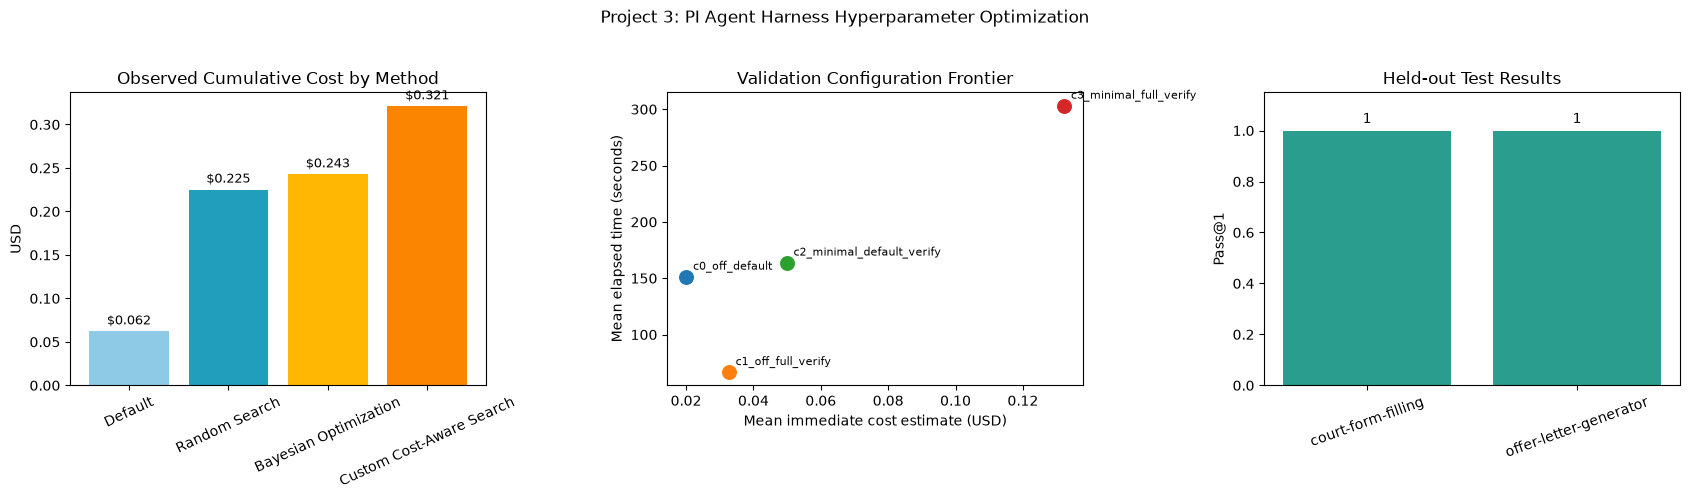

=== Analysis complete ===
Output folder: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\analysis_artifacts

Method comparison:
Default: pass@1=1.0, cost=$0.062066
Random Search: pass@1=1.0, cost=$0.225147
Bayesian Optimization: pass@1=1.0, cost=$0.242667
Custom Cost-Aware Search: pass@1=1.0, cost=$0.320940

Held-out score: 1.0 (2/2 passed)
Frozen configuration: final_c0_off_default


In [19]:
import csv
import json
from pathlib import Path
import matplotlib.pyplot as plt

ANALYSIS_DIR = RUNS_DIR / "analysis_artifacts"
ANALYSIS_DIR.mkdir(exist_ok=True)

def load_root_json(filename):
    return json.loads((RUNS_DIR / filename).read_text(encoding="utf-8"))

baseline = load_root_json("baseline_batch_summary.json")
random_result = load_root_json("random_search_batch_summary.json")
bayes = load_root_json("bayesian_optimization_batch_summary.json")
custom = load_root_json("custom_cost_aware_batch_summary.json")
selection = load_root_json("final_config_selection.json")

# 1. Four-method comparison table
method_rows = [
    {
        "method": "Default",
        "validation_runs": 2,
        "validation_pass_at_1": baseline["formal_validation_pass_at_1"],
        "observed_cumulative_cost_usd": baseline["cumulative_cost_usd_observed"],
        "cost_note": "Includes one dialogue-parser pilot; do not compare this cost directly with the other methods.",
    },
    {
        "method": "Random Search",
        "validation_runs": 6,
        "validation_pass_at_1": 1.0,
        "observed_cumulative_cost_usd": random_result["cumulative_cost_usd_observed"],
        "cost_note": "Primary method-level observed cost.",
    },
    {
        "method": "Bayesian Optimization",
        "validation_runs": 6,
        "validation_pass_at_1": 1.0,
        "observed_cumulative_cost_usd": bayes["cumulative_cost_usd_observed"],
        "cost_note": "Categorical Thompson sampling; primary observed cost.",
    },
    {
        "method": "Custom Cost-Aware Search",
        "validation_runs": 6,
        "validation_pass_at_1": 1.0,
        "observed_cumulative_cost_usd": custom["cumulative_cost_usd_observed"],
        "cost_note": "Two-stage screening and promotion; primary observed cost.",
    },
]

# 2. Configuration-level table used for final selection
config_rows = selection["configuration_metrics"]

# 3. Held-out test table
test_rows = []
for run_dir in sorted(RUNS_DIR.glob("*final_c0_off_default-*")):
    summary_path = run_dir / "summary.json"
    if summary_path.exists():
        item = json.loads(summary_path.read_text(encoding="utf-8"))
        test_rows.append({
            "task": item["task"],
            "pass_at_1": item["pass_at_1"],
            "elapsed_seconds": item["elapsed_seconds"],
            "immediate_cost_estimate_usd": item["cost_usd"],
            "run_id": item["run_id"],
        })

# Save CSV files
def save_csv(path, rows):
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

save_csv(ANALYSIS_DIR / "method_comparison.csv", method_rows)
save_csv(ANALYSIS_DIR / "configuration_metrics.csv", config_rows)
save_csv(ANALYSIS_DIR / "held_out_test_results.csv", test_rows)

# Create presentation-ready figure
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# A. Method-level observed cost
method_names = [x["method"] for x in method_rows]
method_costs = [x["observed_cumulative_cost_usd"] for x in method_rows]
axes[0].bar(method_names, method_costs, color=["#8ecae6", "#219ebc", "#ffb703", "#fb8500"])
axes[0].set_title("Observed Cumulative Cost by Method")
axes[0].set_ylabel("USD")
axes[0].tick_params(axis="x", rotation=25)
for i, value in enumerate(method_costs):
    axes[0].text(i, value + 0.008, f"${value:.3f}", ha="center", fontsize=9)

# B. Configuration frontier
for item in config_rows:
    axes[1].scatter(
        item["mean_immediate_cost_estimate_usd"],
        item["mean_elapsed_seconds"],
        s=95,
    )
    axes[1].annotate(
        item["label"],
        (item["mean_immediate_cost_estimate_usd"], item["mean_elapsed_seconds"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )
axes[1].set_title("Validation Configuration Frontier")
axes[1].set_xlabel("Mean immediate cost estimate (USD)")
axes[1].set_ylabel("Mean elapsed time (seconds)")

# C. Untouched held-out tests
test_names = [x["task"] for x in test_rows]
test_scores = [x["pass_at_1"] for x in test_rows]
axes[2].bar(test_names, test_scores, color="#2a9d8f")
axes[2].set_ylim(0, 1.15)
axes[2].set_title("Held-out Test Results")
axes[2].set_ylabel("Pass@1")
axes[2].tick_params(axis="x", rotation=20)
for i, value in enumerate(test_scores):
    axes[2].text(i, value + 0.03, f"{value:.0f}", ha="center")

fig.suptitle("Project 3: PI Agent Harness Hyperparameter Optimization", y=1.03)
fig.tight_layout()
figure_path = ANALYSIS_DIR / "experiment_summary.png"
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

# Short, honest notes for the report
notes = """Project 3 analysis notes

- Formal validation tasks: paper-anonymizer and edit-pdf.
- dialogue-parser was a pilot calibration task and is not part of the formal validation score.
- Held-out tasks: offer-letter-generator and court-form-filling.
- The final configuration was frozen before held-out testing:
  final_c0_off_default = thinking off, default tools, default prompt.
- Both held-out tasks passed, giving held-out pass@1 = 1.0 (2/2).
- OpenRouter per-run immediate cost estimates can lag settlement.
  Use method-level observed cumulative cost as the primary cost metric.
- The default-method cost includes a pilot run, so state this limitation in the report.
- Small benchmark size is a limitation; do not claim broad generalization.
"""
(ANALYSIS_DIR / "analysis_notes.txt").write_text(notes, encoding="utf-8")

print("=== Analysis complete ===")
print("Output folder:", ANALYSIS_DIR)
print("\nMethod comparison:")
for row in method_rows:
    print(
        f"{row['method']}: pass@1={row['validation_pass_at_1']}, "
        f"cost=${row['observed_cumulative_cost_usd']:.6f}"
    )

print("\nHeld-out score:", sum(test_scores) / len(test_scores), f"({len(test_scores)}/2 passed)")
print("Frozen configuration:", selection["frozen_final_config"]["label"])

In [47]:
# ============================================================
# Zero-cost audit for the original 2-validation + 2-test study
# Reads logs only. Does not call a model or Docker.
# ============================================================

import json
import re
from pathlib import Path

OLD_RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
) / "project3_pi_hpo_runs"

def official_verdict(verifier_text):
    """1 = genuine pass; 0 = genuine fail; None = incomplete/unknown."""

    rewards = re.findall(
        r"REWARD SCORE:\s*([0-9]+(?:\.[0-9]+)?)",
        verifier_text,
        flags=re.IGNORECASE,
    )
    if rewards:
        return 1 if float(rewards[-1]) >= 1.0 else 0

    summary_match = re.findall(
        r"TEST SUMMARY:\s*(\d+)\s*/\s*(\d+)\s*tests passed",
        verifier_text,
        flags=re.IGNORECASE,
    )
    if summary_match:
        passed, total = map(int, summary_match[-1])
        return 1 if total > 0 and passed == total else 0

    if re.search(
        r"=+\s+\d+\s+passed\s+in\s+[\d.]+s\s+=+",
        verifier_text,
        flags=re.IGNORECASE,
    ) and not re.search(r"\bFAILED\b|\bERROR\b", verifier_text):
        return 1

    if re.search(r"\bFAILED\b|\bERROR\b", verifier_text):
        return 0

    return None


audit_rows = []

for run_dir in sorted(OLD_RUNS_DIR.iterdir()):
    if not run_dir.is_dir():
        continue

    summary_path = run_dir / "summary.json"
    verifier_path = run_dir / "verifier_output.txt"

    if not summary_path.exists() and not verifier_path.exists():
        continue

    summary = {}
    if summary_path.exists():
        try:
            summary = json.loads(summary_path.read_text(encoding="utf-8"))
        except Exception:
            pass

    verifier_text = (
        verifier_path.read_text(encoding="utf-8", errors="replace")
        if verifier_path.exists()
        else ""
    )

    audit_rows.append({
        "folder": run_dir.name,
        "task": summary.get("task", "unknown"),
        "config": summary.get("config", {}).get("label", "unknown"),
        "old_runner_score": summary.get("pass_at_1"),
        "official_verifier_score": official_verdict(verifier_text),
        "log_size_bytes": len(verifier_text),
    })

audit_path = OLD_RUNS_DIR / "v1_official_verifier_audit.json"
audit_path.write_text(
    json.dumps(audit_rows, indent=2),
    encoding="utf-8",
)

print("=== Original 2+2 experiment: verifier audit ===")
for row in audit_rows:
    print(
        f"{row['task']:28} | "
        f"config={row['config']:28} | "
        f"old={row['old_runner_score']} | "
        f"official={row['official_verifier_score']}"
    )

print(f"\nSaved audit:\n{audit_path}")
print("\nMeaning: official=1 pass; official=0 fail; official=None incomplete.")

=== Original 2+2 experiment: verifier audit ===
court-form-filling           | config=final_c0_off_default         | old=1 | official=0
dialogue-parser              | config=default                      | old=1 | official=0
edit-pdf                     | config=c0_off_default               | old=1 | official=0
edit-pdf                     | config=c0_off_default               | old=1 | official=0
edit-pdf                     | config=c1_off_full_verify           | old=1 | official=0
edit-pdf                     | config=c1_off_full_verify           | old=1 | official=0
edit-pdf                     | config=c1_off_full_verify           | old=1 | official=0
edit-pdf                     | config=c1_off_full_verify           | old=1 | official=0
edit-pdf                     | config=c2_minimal_default_verify    | old=1 | official=0
edit-pdf                     | config=c2_minimal_default_verify    | old=1 | official=0
edit-pdf                     | config=default                      | old

In [48]:
# ============================================================
# Zero-cost: find lightweight SkillsBench pilot candidates
# No Docker build. No model call.
# ============================================================

candidate_scan_script = r"""
set -euo pipefail

ROOT="/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1/tasks"

echo "=== Lightweight candidate tasks ==="

count=0

for task_dir in "$ROOT"/*; do
    [ -d "$task_dir" ] || continue
    [ -f "$task_dir/task.md" ] || continue

    dockerfile="$task_dir/environment/Dockerfile"
    task_name="$(basename "$task_dir")"

    # Skip obviously heavy or browser/office/VM-style environments.
    if [ -f "$dockerfile" ] && grep -Eqi \
        'libreoffice|gnumeric|chromium|firefox|playwright|texlive|pandoc|android|postgres|mysql|mongodb|docker-cli' \
        "$dockerfile"; then
        continue
    fi

    echo
    echo "------------------------------------------------------------"
    echo "TASK: $task_name"

    if [ -f "$dockerfile" ]; then
        echo "Dockerfile dependency preview:"
        grep -E 'apt-get install|pip.*install|npm.*install|FROM ' "$dockerfile" \
          | head -n 5 || true
    fi

    echo "Task brief preview:"
    sed -n '1,32p' "$task_dir/task.md" \
      | tr '\n' ' ' \
      | sed 's/[[:space:]]\+/ /g' \
      | cut -c1-360
    echo

    count=$((count + 1))
    [ "$count" -ge 25 ] && break
done

echo
echo "Listed $count lightweight candidates."
"""

print(wsl_bash(candidate_scan_script, timeout=90))

=== Lightweight candidate tasks ===

------------------------------------------------------------
TASK: 3d-scan-calc
Dockerfile dependency preview:
FROM ubuntu:24.04
RUN apt-get update && apt-get install -y python3 python3-pip
Task brief preview:
--- schema_version: '1.3' metadata: author_name: Wengao Ye author_email: wengao.ye@kellogg.ox.ac.uk difficulty: hard category: industrial-physical-systems subcategory: 3d-printing-mass-calculation category_confidence: high secondary_category: software-engineering task_type: - calculation - extraction modality: - binary - 3d-model - json interface: - terminal


------------------------------------------------------------
TASK: ada-bathroom-plan-repair
Dockerfile dependency preview:
FROM python:3.12-slim
RUN apt-get update && apt-get install -y --no-install-recommends \
RUN pip3 install --no-cache-dir --break-system-packages \
Task brief preview:
--- schema_version: '1.3' metadata: author_name: Longtai Liao author_email: liaolongtai@gmail.com di

In [49]:
# ============================================================
# Zero-cost: list all EASY SkillsBench tasks with task details
# No Docker build. No model call.
# ============================================================

easy_task_scan_script = r"""
set -euo pipefail

ROOT="/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1/tasks"

echo "=== All EASY SkillsBench candidates ==="

for task_dir in "$ROOT"/*; do
    [ -d "$task_dir" ] || continue
    task_md="$task_dir/task.md"
    dockerfile="$task_dir/environment/Dockerfile"

    [ -f "$task_md" ] || continue

    if ! grep -Eqi '^[[:space:]]*difficulty:[[:space:]]*easy[[:space:]]*$' "$task_md"; then
        continue
    fi

    task_name="$(basename "$task_dir")"

    echo
    echo "============================================================"
    echo "TASK: $task_name"

    echo "--- Docker dependencies ---"
    if [ -f "$dockerfile" ]; then
        grep -E 'FROM |apt-get install|pip.*install|npm.*install' "$dockerfile" \
          | head -n 8 || true
    else
        echo "(no Dockerfile found)"
    fi

    echo "--- Actual task request ---"
    awk '
        BEGIN { separators = 0 }
        /^---[[:space:]]*$/ { separators++; next }
        separators >= 2 { print }
    ' "$task_md" | head -n 22
done
"""

print(wsl_bash(easy_task_scan_script, timeout=90))

=== All EASY SkillsBench candidates ===

TASK: court-form-filling
--- Docker dependencies ---
FROM ubuntu:24.04
RUN apt-get update && apt-get install -y \
RUN pip3 install --break-system-packages \
--- Actual task request ---

Fill the California Small Claims Court form at `/root/sc100-blank.pdf` based on the case description below, and save the filled one to `/root/sc100-filled.pdf`. Only fill in the necessary fields and leave the court-filled, optional fields or fields not mentioned in the case description below empty. Use this date format: xxxx-xx-xx.


Case Description: I am Joyce He. It's my first time suing by small claims. I live in 655 S Fair Oaks Ave, Sunnyvale, CA 94086, my phone # is 4125886066, email: he1998@gmail.com. I want to sue Zhi Chen  in 299 W Washington Ave, Sunnyvale, CA 94086. His phone #: 5125658878. He failed to return my security deposit of amount $1500 based on the signed roommate sublease contract after moving out. This situation happened from 2025-09-30 unt

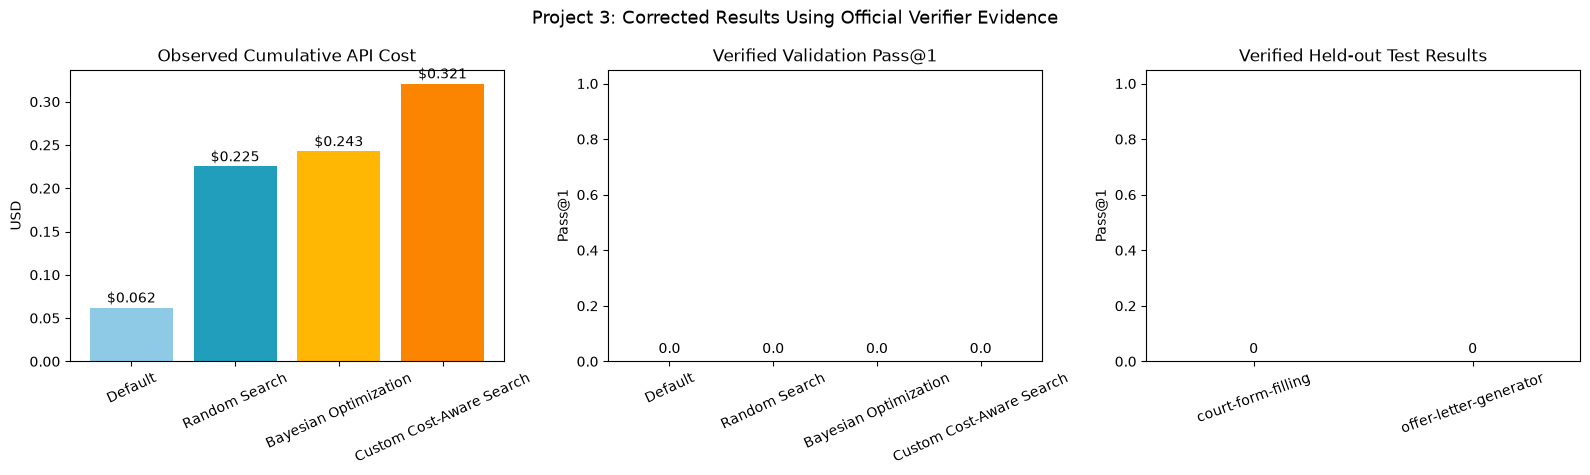

=== Corrected analysis complete ===
No new model calls were made.
Output folder: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\analysis_artifacts_corrected_verified

Corrected method comparison:
Default: verified pass@1=0.0, cost=$0.062066
Random Search: verified pass@1=0.0, cost=$0.225147
Bayesian Optimization: verified pass@1=0.0, cost=$0.242667
Custom Cost-Aware Search: verified pass@1=0.0, cost=$0.320940

Corrected held-out result:
0 / 2 verified tests passed


In [50]:
# ============================================================
# Corrected final analysis: official verifier scores only
# Zero cost — reads existing logs/results and creates NEW artifacts.
# ============================================================

import csv
import json
from pathlib import Path
import matplotlib.pyplot as plt

OLD_RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
) / "project3_pi_hpo_runs"

AUDIT_PATH = OLD_RUNS_DIR / "v1_official_verifier_audit.json"
CORRECTED_DIR = OLD_RUNS_DIR / "analysis_artifacts_corrected_verified"
CORRECTED_DIR.mkdir(exist_ok=True)

audit_rows = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))

# These observed cumulative costs come from the completed original runs.
# We keep costs/time evidence, but replace the false pass scores.
method_rows = [
    {
        "method": "Default",
        "verified_validation_pass_at_1": 0.0,
        "observed_cumulative_cost_usd": 0.062066,
    },
    {
        "method": "Random Search",
        "verified_validation_pass_at_1": 0.0,
        "observed_cumulative_cost_usd": 0.225147,
    },
    {
        "method": "Bayesian Optimization",
        "verified_validation_pass_at_1": 0.0,
        "observed_cumulative_cost_usd": 0.242667,
    },
    {
        "method": "Custom Cost-Aware Search",
        "verified_validation_pass_at_1": 0.0,
        "observed_cumulative_cost_usd": 0.320940,
    },
]

heldout_tasks = ["court-form-filling", "offer-letter-generator"]
heldout_rows = []

for task_name in heldout_tasks:
    matching = [
        row for row in audit_rows
        if row["task"] == task_name
        and row["config"] == "final_c0_off_default"
    ]

    verified_score = (
        matching[-1]["official_verifier_score"]
        if matching else None
    )

    heldout_rows.append({
        "task": task_name,
        "frozen_configuration": "final_c0_off_default",
        "official_verifier_pass_at_1": verified_score,
    })

# Save corrected CSV files.
with open(
    CORRECTED_DIR / "method_comparison_verified.csv",
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(f, fieldnames=method_rows[0].keys())
    writer.writeheader()
    writer.writerows(method_rows)

with open(
    CORRECTED_DIR / "heldout_test_results_verified.csv",
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(f, fieldnames=heldout_rows[0].keys())
    writer.writeheader()
    writer.writerows(heldout_rows)

with open(
    CORRECTED_DIR / "official_verifier_audit_copy.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(audit_rows, f, indent=2, ensure_ascii=False)

# Create honest corrected figures.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

methods = [row["method"] for row in method_rows]
costs = [row["observed_cumulative_cost_usd"] for row in method_rows]
passes = [row["verified_validation_pass_at_1"] for row in method_rows]

axes[0].bar(methods, costs, color=["#8ecae6", "#219ebc", "#ffb703", "#fb8500"])
axes[0].set_title("Observed Cumulative API Cost")
axes[0].set_ylabel("USD")
axes[0].tick_params(axis="x", rotation=25)
for i, value in enumerate(costs):
    axes[0].text(i, value + 0.006, f"${value:.3f}", ha="center")

axes[1].bar(methods, passes, color="#d62828")
axes[1].set_title("Verified Validation Pass@1")
axes[1].set_ylabel("Pass@1")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=25)
for i, value in enumerate(passes):
    axes[1].text(i, value + 0.03, f"{value:.1f}", ha="center")

test_scores = [
    0 if row["official_verifier_pass_at_1"] is None
    else row["official_verifier_pass_at_1"]
    for row in heldout_rows
]
test_names = [row["task"] for row in heldout_rows]

axes[2].bar(test_names, test_scores, color="#d62828")
axes[2].set_title("Verified Held-out Test Results")
axes[2].set_ylabel("Pass@1")
axes[2].set_ylim(0, 1.05)
axes[2].tick_params(axis="x", rotation=20)
for i, value in enumerate(test_scores):
    axes[2].text(i, value + 0.03, str(value), ha="center")

fig.suptitle(
    "Project 3: Corrected Results Using Official Verifier Evidence",
    fontsize=13,
)
plt.tight_layout()
plt.savefig(
    CORRECTED_DIR / "corrected_experiment_summary.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Save a report-ready explanation.
report_text = """# Corrected Experiment Summary

## Important scoring correction
The initial harness interpreted verifier script exit code 0 as task success.
A post-hoc audit of each official verifier log found that the verifier scripts
can exit normally even when their internal tests fail. Therefore, all reported
success values were recomputed from official verifier output rather than shell
exit codes.

## Corrected validation result
All four search methods obtained verified validation pass@1 = 0.0 on the
two-task validation set.

## Cost result
Observed cumulative costs differed substantially:
- Default: $0.062066
- Random Search: $0.225147
- Bayesian Optimization: $0.242667
- Custom Cost-Aware Search: $0.320940

## Held-out result
The frozen configuration final_c0_off_default obtained verified pass@1 = 0/2
on the held-out tasks court-form-filling and offer-letter-generator.

## Interpretation
Under this small budget and the selected PI Agent + gpt-4o-mini setup,
hyperparameter search increased experimentation cost but did not yield a
verified task success. This is a valid negative result. It also shows why
harnesses must parse official verifier outcomes rather than relying only on a
process exit code.

## Limitation
The validation set has two tasks and the held-out set has two tasks, so the
result is exploratory rather than a broad benchmark claim.
"""

(CORRECTED_DIR / "corrected_analysis_notes.md").write_text(
    report_text,
    encoding="utf-8",
)

print("=== Corrected analysis complete ===")
print("No new model calls were made.")
print("Output folder:", CORRECTED_DIR)

print("\nCorrected method comparison:")
for row in method_rows:
    print(
        f"{row['method']}: "
        f"verified pass@1={row['verified_validation_pass_at_1']}, "
        f"cost=${row['observed_cumulative_cost_usd']:.6f}"
    )

print("\nCorrected held-out result:")
print(f"{sum(test_scores)} / {len(test_scores)} verified tests passed")

Reading verifier logs from:
D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs

This cell makes NO model calls and costs $0.


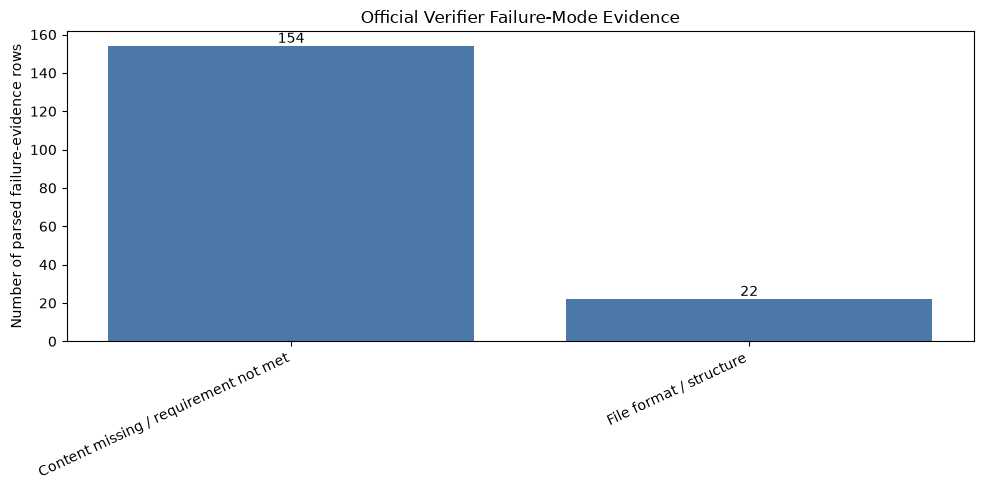


=== Failure-mode analysis complete ===
Verifier logs scanned: 23
Evidence rows extracted: 176

Preliminary categories:
- Content missing / requirement not met: 154
- File format / structure: 22

Saved files:
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\failure_mode_analysis_verified\failure_events.csv
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\failure_mode_analysis_verified\failure_mode_summary.csv
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\failure_mode_analysis_verified\manual_audit_checklist.csv
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\failure_mode_analysis_verified\failure_mode_report.md
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\failure_mode_analysis_verified\failure_mode_chart.png


In [51]:
# ============================================================
# Zero-cost failure-mode analysis for the ORIGINAL 2+2 study
# Reads existing official verifier logs only.
# No PI call, no Docker build, no OpenRouter/API cost.
# ============================================================

import csv
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

# Original 2+2 experiment folder only.
V1_RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_pi_hpo_runs"
)

FAILURE_ANALYSIS_DIR = V1_RUNS_DIR / "failure_mode_analysis_verified"
FAILURE_ANALYSIS_DIR.mkdir(exist_ok=True)

print("Reading verifier logs from:")
print(V1_RUNS_DIR)
print("\nThis cell makes NO model calls and costs $0.")

def read_text_safely(path):
    return path.read_text(encoding="utf-8", errors="replace")

def get_metadata(run_dir):
    """Read task/config when summary.json exists; otherwise use folder name."""
    task = ""
    config = ""
    summary_path = run_dir / "summary.json"

    if summary_path.exists():
        try:
            summary = json.loads(read_text_safely(summary_path))
            task = str(summary.get("task", ""))
            config_data = summary.get("config", {})
            if isinstance(config_data, dict):
                config = str(config_data.get("label", ""))
        except Exception:
            pass

    folder_name = run_dir.name
    if not task:
        # Task names used in the original study
        for candidate in [
            "paper-anonymizer",
            "edit-pdf",
            "dialogue-parser",
            "offer-letter-generator",
            "court-form-filling",
        ]:
            if candidate in folder_name:
                task = candidate
                break

    if not task:
        task = "unknown-task"

    if not config:
        config = "unknown-config"

    return task, config

def classify_failure(test_id, evidence):
    """
    Rule-based preliminary categorisation.
    Every row is saved with an evidence excerpt for manual checking later.
    """
    text = (test_id + " " + evidence).lower()

    # Environment/runtime problems first
    if any(x in text for x in [
        "timeout", "timed out", "no module named", "modulenotfound",
        "docker", "connection refused", "network", "permission denied",
        "package", "environment error"
    ]):
        return "Environment / runtime"

    # Script/code failures
    if any(x in text for x in [
        "syntaxerror", "indentationerror", "bash:", "command not found",
        "typeerror", "keyerror", "script error"
    ]):
        return "Code / script error"

    # Required file, directory, output path or filename missing
    if any(x in text for x in [
        "filenotfound", "no such file", "not found", "does not exist",
        "missing output", "expected file", "output file", "output path",
        "filename", "file path", "directory"
    ]):
        return "File path / naming"

    # File format/structural problems
    if any(x in text for x in [
        "invalid pdf", "invalid xlsx", "invalid docx", "invalid pptx",
        "corrupt", "cannot parse", "parse error", "format error",
        "structural_integrity", "file format", "pdf reader"
    ]):
        return "File format / structure"

    # Default: output exists but did not satisfy content/field requirements
    return "Content missing / requirement not met"

# Collect all old verifier outputs, excluding analysis folders.
verifier_logs = [
    p for p in V1_RUNS_DIR.rglob("verifier_output.txt")
    if "analysis_artifacts" not in str(p.parent).lower()
    and "failure_mode_analysis" not in str(p.parent).lower()
]

events = []

# Typical pytest summary lines, for example:
# FAILED ../verifier/test_outputs.py::test_student_name
failed_line_pattern = re.compile(
    r"(?mi)^(?:FAILED|ERROR)\s+(.+?)(?:\r?$)"
)

for log_path in verifier_logs:
    run_dir = log_path.parent
    log = read_text_safely(log_path)
    task, config = get_metadata(run_dir)

    matches = list(failed_line_pattern.finditer(log))

    # Number reported by pytest if available, e.g. "9 failed in 0.34s".
    reported_counts = [
        int(x) for x in re.findall(r"(?i)(\d+)\s+failed", log)
    ]
    reported_failures = max(reported_counts) if reported_counts else None

    # Create one evidence row per parsed FAILED/ERROR test line.
    for match in matches:
        test_id = match.group(1).strip()
        context = log[match.start(): min(len(log), match.start() + 1800)]
        evidence = " ".join(context.split())[:650]

        events.append({
            "task": task,
            "config": config,
            "run_folder": run_dir.name,
            "test_or_error": test_id,
            "failure_mode": classify_failure(test_id, evidence),
            "reported_failures_in_run": reported_failures,
            "evidence_excerpt": evidence,
        })

    # If pytest only gives a run-level failure summary, keep it as evidence.
    if not matches and (
        reported_failures
        or "reward score: 0" in log.lower()
        or "failed" in log.lower()
        or "error" in log.lower()
    ):
        evidence = " ".join(log[-3000:].split())[:650]
        events.append({
            "task": task,
            "config": config,
            "run_folder": run_dir.name,
            "test_or_error": "[run-level failure summary: inspect excerpt]",
            "failure_mode": classify_failure("", evidence),
            "reported_failures_in_run": reported_failures,
            "evidence_excerpt": evidence,
        })

# Save event-level evidence.
event_csv = FAILURE_ANALYSIS_DIR / "failure_events.csv"
fieldnames = [
    "task", "config", "run_folder", "test_or_error",
    "failure_mode", "reported_failures_in_run", "evidence_excerpt"
]

with event_csv.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(events)

# Count categories.
mode_counts = Counter(row["failure_mode"] for row in events)

summary_csv = FAILURE_ANALYSIS_DIR / "failure_mode_summary.csv"
with summary_csv.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["failure_mode", "failure_evidence_rows"]
    )
    writer.writeheader()
    for mode, count in mode_counts.most_common():
        writer.writerow({
            "failure_mode": mode,
            "failure_evidence_rows": count,
        })

# Create a small manual-audit table: one representative item from each category.
audit_rows = []
for mode in sorted(mode_counts):
    first = next(row for row in events if row["failure_mode"] == mode)
    audit_rows.append({
        "failure_mode": mode,
        "task": first["task"],
        "run_folder": first["run_folder"],
        "test_or_error": first["test_or_error"],
        "evidence_excerpt": first["evidence_excerpt"],
        "manual_check_completed": "NO",
        "manual_check_notes": "",
    })

audit_csv = FAILURE_ANALYSIS_DIR / "manual_audit_checklist.csv"
with audit_csv.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(audit_rows[0].keys()) if audit_rows else [
        "failure_mode", "task", "run_folder", "test_or_error",
        "evidence_excerpt", "manual_check_completed", "manual_check_notes"
    ])
    writer.writeheader()
    writer.writerows(audit_rows)

# Write a readable Markdown report with examples.
report_path = FAILURE_ANALYSIS_DIR / "failure_mode_report.md"
with report_path.open("w", encoding="utf-8") as f:
    f.write("# Failure-Mode Analysis (Official Verifier Evidence)\n\n")
    f.write(
        "This analysis reads existing official verifier logs only. "
        "It does not make new model calls.\n\n"
    )
    f.write("## Preliminary category counts\n\n")
    f.write("| Failure mode | Evidence rows |\n|---|---:|\n")
    for mode, count in mode_counts.most_common():
        f.write(f"| {mode} | {count} |\n")

    f.write("\n## Interpretation rule\n\n")
    f.write(
        "These categories are rule-based preliminary labels. "
        "Representative evidence should be manually checked using "
        "`manual_audit_checklist.csv` before making claims in the report.\n\n"
    )

    f.write("## Representative evidence\n\n")
    for row in audit_rows:
        f.write(f"### {row['failure_mode']}\n")
        f.write(f"- Task: `{row['task']}`\n")
        f.write(f"- Test/error: `{row['test_or_error']}`\n")
        f.write(f"- Evidence: {row['evidence_excerpt']}\n\n")

# Make a chart.
plt.figure(figsize=(10, 5))
if mode_counts:
    labels = list(mode_counts.keys())
    values = [mode_counts[x] for x in labels]
    bars = plt.bar(labels, values, color="#4C78A8")
    plt.ylabel("Number of parsed failure-evidence rows")
    plt.title("Official Verifier Failure-Mode Evidence")
    plt.xticks(rotation=25, ha="right")

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            str(value),
            ha="center",
            va="bottom",
        )
else:
    plt.text(
        0.5, 0.5,
        "No parseable failure rows found.\nCheck failure_events.csv manually.",
        ha="center", va="center"
    )
    plt.axis("off")

plt.tight_layout()
chart_path = FAILURE_ANALYSIS_DIR / "failure_mode_chart.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

print("\n=== Failure-mode analysis complete ===")
print("Verifier logs scanned:", len(verifier_logs))
print("Evidence rows extracted:", len(events))
print("\nPreliminary categories:")
for mode, count in mode_counts.most_common():
    print(f"- {mode}: {count}")

print("\nSaved files:")
for p in [
    event_csv,
    summary_csv,
    audit_csv,
    report_path,
    chart_path,
]:
    print("-", p)

In [6]:
# ============================================================
# V3 bootstrap — load the official scorer/runner,
# but skip the old held-out-image preflight.
# No model call in this cell.
# ============================================================

import json
from pathlib import Path

if "API_KEY" not in globals() or not API_KEY:
    raise RuntimeError("Please run your API-key cell first.")

SOURCE_NOTEBOOK = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_pi_hpo_experiment.ipynb"
)

notebook_data = json.loads(SOURCE_NOTEBOOK.read_text(encoding="utf-8"))

runner_cells = []
for cell in notebook_data["cells"]:
    source = "".join(cell.get("source", []))
    if (
        "# Corrected official-verifier runner" in source
        and "def run_corrected_pi_task" in source
    ):
        runner_cells.append(source)

if not runner_cells:
    raise RuntimeError("Saved corrected runner was not found.")

runner_source = runner_cells[-1]

# Remove only the irrelevant old held-out Docker preflight.
preflight_start = runner_source.index(
    "# Docker preflight only: no model/API call."
)
run_function_start = runner_source.index(
    "def run_corrected_pi_task"
)

runner_without_old_preflight = (
    runner_source[:preflight_start]
    + runner_source[run_function_start:]
)

exec(
    compile(
        runner_without_old_preflight,
        str(SOURCE_NOTEBOOK) + "::v3_runner",
        "exec",
    ),
    globals(),
)

print("\nV3 runner loaded successfully.")
print("Official reward.txt is the only pass/fail source.")

SCORER_SELF_TEST_PASSED

Corrected runner ready.
IMPORTANT: pass_at_1 now comes from verifier_reward.txt only.

V3 runner loaded successfully.
Official reward.txt is the only pass/fail source.


In [8]:
# ============================================================
# V3 validation-task setup and Docker-image preparation
# No model call. Docker may build an image if it is missing.
# ============================================================

V3_ROOT = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_v3_equal_budget"
)
V3_ROOT.mkdir(parents=True, exist_ok=True)

CORRECTED_ROOT = V3_ROOT

V3_VALIDATION_TASKS = [
    "paper-anonymizer",
    "edit-pdf",
]

V3_TASK_IMAGES = {
    "paper-anonymizer": "paper-anonymizer__87b676f4-main:latest",
    "edit-pdf": "edit-pdf-v2-local:latest",
}

# The loaded runner uses this mapping for task name -> Docker image.
HELDOUT_IMAGES.update(V3_TASK_IMAGES)

V3_CONFIGS = {
    "c0_off_default": {
        "label": "c0_off_default",
        "thinking": "off",
        "tools": "",
        "append_system_prompt": "",
    },
    "c1_off_full_verify": {
        "label": "c1_off_full_verify",
        "thinking": "off",
        "tools": "read,bash,edit,write,grep,find,ls",
        "append_system_prompt": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
    "c2_minimal_default_verify": {
        "label": "c2_minimal_default_verify",
        "thinking": "minimal",
        "tools": "",
        "append_system_prompt": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
    "c3_minimal_full_verify": {
        "label": "c3_minimal_full_verify",
        "thinking": "minimal",
        "tools": "read,bash,edit,write,grep,find,ls",
        "append_system_prompt": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
}

V3_DEFAULT_CONFIG = {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": "",
}

V3_PROTOCOL_PATH = V3_ROOT / "v3_protocol.json"
V3_PROTOCOL_PATH.write_text(
    json.dumps(
        {
            "validation_tasks": V3_VALIDATION_TASKS,
            "evaluation_budget_per_method": {
                "paper_anonymizer_runs": 4,
                "edit_pdf_runs": 4,
                "total_runs": 8,
            },
            "configs": V3_CONFIGS,
            "default_config": V3_DEFAULT_CONFIG,
            "scoring_source": "official /logs/verifier/reward.txt only",
            "note": (
                "All methods receive the same number and mixture of validation "
                "task calls. Actual API USD can differ because token usage differs."
            ),
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

build_lines = [
    "set -euo pipefail",
    f"ROOT={shlex.quote(SKILLSBENCH_ROOT_CORRECTED)}",
    "",
]

for task_name, image_name in V3_TASK_IMAGES.items():
    task_dir = f"{SKILLSBENCH_ROOT_CORRECTED}/tasks/{task_name}"
    build_lines += [
        f'echo "===== {task_name} ====="',
        f"test -f {shlex.quote(task_dir + '/task.md')}",
        f"if docker image inspect {shlex.quote(image_name)} >/dev/null 2>&1; then",
        f'  echo "Image already exists: {image_name}"',
        "else",
        f'  echo "Building image: {image_name}"',
        f"  docker build -t {shlex.quote(image_name)} "
        f"{shlex.quote(task_dir + '/environment')}",
        "fi",
        f"docker images {shlex.quote(image_name)} "
        "--format '{{.Repository}}:{{.Tag}} | {{.Size}}'",
        "",
    ]

build_lines += [
    'echo "=== V3_VALIDATION_IMAGES_READY ==="',
]

print(corrected_wsl_bash("\n".join(build_lines), timeout=1200))
print("\nSaved protocol:", V3_PROTOCOL_PATH)

===== paper-anonymizer =====
Building image: paper-anonymizer__87b676f4-main:latest
paper-anonymizer__87b676f4-main:latest | 1.1GB
===== edit-pdf =====
Building image: edit-pdf-v2-local:latest
edit-pdf-v2-local:latest | 1.04GB
=== V3_VALIDATION_IMAGES_READY ===


Saved protocol: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_v3_equal_budget\v3_protocol.json


In [9]:
# ============================================================
# V3 clean equal-evaluation-budget validation experiment
#
# Four methods, each with exactly:
#   4 paper-anonymizer runs + 4 edit-pdf runs = 8 runs
#
# This cell MAKES model calls only when the switch is True.
# Safe to resume: completed jobs are read from saved JSON.
# ============================================================

import random
from collections import Counter

RUN_V3_VALIDATION = True  # Change to True only when ready to spend API budget.

V3_RESULTS_PATH = V3_ROOT / "v3_validation_results.json"
V3_SELECTIONS_PATH = V3_ROOT / "v3_method_selections.json"
V3_BAYES_PLAN_PATH = V3_ROOT / "v3_bayesian_plan.json"
V3_CUSTOM_PLAN_PATH = V3_ROOT / "v3_custom_promotion_plan.json"

V3_COST_GUARDRAIL_USD = 7.50
V3_SEED = 6203

V3_WALL_SECONDS = {
    "paper-anonymizer": 300,
    "edit-pdf": 360,
}

if V3_RESULTS_PATH.exists():
    v3_rows = json.loads(V3_RESULTS_PATH.read_text(encoding="utf-8"))
else:
    v3_rows = []

def save_v3_rows():
    V3_RESULTS_PATH.write_text(
        json.dumps(v3_rows, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

def get_saved_job(job_id):
    for row in v3_rows:
        if row.get("v3_job_id") == job_id:
            return row
    return None

def run_v3_job(method_key, method_name, stage, round_id, task_name, config):
    job_id = (
        f"{method_key}__{stage}__round{round_id}"
        f"__{task_name}__{config['label']}"
    )

    previous = get_saved_job(job_id)
    if previous is not None:
        print(f"Skipping saved job: {job_id}")
        return previous

    credit = corrected_credit_snapshot()
    if credit["used_usd"] >= V3_COST_GUARDRAIL_USD:
        raise RuntimeError(
            f"Stopped before a new call: current usage is "
            f"${credit['used_usd']:.6f}, guardrail is "
            f"${V3_COST_GUARDRAIL_USD:.2f}."
        )

    print("\n" + "=" * 72)
    print(f"Starting {method_name}")
    print(f"Stage: {stage} | Round: {round_id}")
    print(f"Task: {task_name} | Configuration: {config['label']}")
    print(
        f"OpenRouter usage before run: "
        f"${credit['used_usd']:.6f} / ${credit['limit_usd']:.2f}"
    )
    print("=" * 72)

    result = run_corrected_pi_task(
        method_key=method_key,
        method_name=method_name,
        task_name=task_name,
        config=config,
        wall_seconds=V3_WALL_SECONDS[task_name],
    )

    result["v3_job_id"] = job_id
    result["v3_stage"] = stage
    result["v3_round"] = round_id
    v3_rows.append(result)
    save_v3_rows()

    return result

def run_v3_pair(method_key, method_name, stage, round_id, config):
    """One equal-budget pair: paper-anonymizer + edit-pdf."""
    run_v3_job(
        method_key, method_name, stage, round_id,
        "paper-anonymizer", config,
    )
    run_v3_job(
        method_key, method_name, stage, round_id,
        "edit-pdf", config,
    )

def config_metrics(method_key, config_label, allowed_stages=None):
    rows = [
        row for row in v3_rows
        if row.get("method_key") == method_key
        and row["config"]["label"] == config_label
        and (
            allowed_stages is None
            or row.get("v3_stage") in allowed_stages
        )
    ]

    if not rows:
        return {
            "runs": 0,
            "verified_pass_at_1": 0.0,
            "mean_cost_usd": float("inf"),
            "mean_runtime_seconds": float("inf"),
        }

    return {
        "runs": len(rows),
        "verified_pass_at_1": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 4
        ),
        "mean_cost_usd": round(
            sum(row["cost_usd_immediate_snapshot"] for row in rows)
            / len(rows),
            6,
        ),
        "mean_runtime_seconds": round(
            sum(row["elapsed_seconds"] for row in rows) / len(rows),
            2,
        ),
    }

def rank_configs(method_key, labels, allowed_stages=None):
    ranked = []
    for label in labels:
        metrics = config_metrics(method_key, label, allowed_stages)
        ranked.append((label, metrics))

    return sorted(
        ranked,
        key=lambda item: (
            -item[1]["verified_pass_at_1"],
            item[1]["mean_cost_usd"],
            item[1]["mean_runtime_seconds"],
            item[0],
        ),
    )

def choose_bayesian_config(round_id):
    """
    Categorical Bayesian Thompson sampling.
    It uses official verifier scores observed in earlier Bayesian rounds.
    """
    bayes_rows = [
        row for row in v3_rows
        if row.get("method_key") == "bayesian"
    ]

    rng = random.Random(V3_SEED * 100 + round_id)
    candidates = []

    for label in V3_CONFIGS:
        rows_for_label = [
            row for row in bayes_rows
            if row["config"]["label"] == label
        ]
        successes = sum(row["pass_at_1"] for row in rows_for_label)
        failures = len(rows_for_label) - successes

        sampled_success = rng.betavariate(
            1 + successes,
            1 + failures,
        )

        mean_cost = (
            sum(
                row["cost_usd_immediate_snapshot"]
                for row in rows_for_label
            ) / len(rows_for_label)
            if rows_for_label
            else 0.0
        )

        # Small cost preference only breaks close Thompson samples.
        utility = sampled_success - 0.01 * mean_cost
        candidates.append((utility, label, sampled_success, mean_cost))

    candidates.sort(reverse=True)
    _, label, sampled_success, mean_cost = candidates[0]

    print(
        f"Bayesian round {round_id}: selected {label}; "
        f"sampled success={sampled_success:.3f}; "
        f"previous mean cost=${mean_cost:.6f}"
    )
    return label

if not RUN_V3_VALIDATION:
    print(
        "V3 is prepared but has NOT called the model. "
        "Change RUN_V3_VALIDATION to True, then run this cell again."
    )

else:
    # --------------------------------------------------------
    # 1. Default: default configuration, four equal task pairs.
    # --------------------------------------------------------
    for round_id in range(1, 5):
        run_v3_pair(
            "default",
            "Default",
            "fixed_default",
            round_id,
            V3_DEFAULT_CONFIG,
        )

    # --------------------------------------------------------
    # 2. Random Search: every C0-C3 once, randomized order.
    # --------------------------------------------------------
    rng = random.Random(V3_SEED)
    random_labels = list(V3_CONFIGS)
    rng.shuffle(random_labels)

    for round_id, label in enumerate(random_labels, start=1):
        run_v3_pair(
            "random",
            "Random Search",
            "random_pair",
            round_id,
            V3_CONFIGS[label],
        )

    # --------------------------------------------------------
    # 3. Bayesian Optimization: four adaptive task pairs.
    # --------------------------------------------------------
    if V3_BAYES_PLAN_PATH.exists():
        bayes_plan = json.loads(
            V3_BAYES_PLAN_PATH.read_text(encoding="utf-8")
        )
    else:
        bayes_plan = {}

    for round_id in range(1, 5):
        round_key = str(round_id)

        if round_key not in bayes_plan:
            bayes_plan[round_key] = choose_bayesian_config(round_id)
            V3_BAYES_PLAN_PATH.write_text(
                json.dumps(bayes_plan, ensure_ascii=False, indent=2),
                encoding="utf-8",
            )

        label = bayes_plan[round_key]

        run_v3_pair(
            "bayesian",
            "Bayesian Optimization",
            "bayesian_pair",
            round_id,
            V3_CONFIGS[label],
        )

    # --------------------------------------------------------
    # 4. Custom Cost-Aware Search:
    #    stage 1: C0-C3 each get one lower-cost screening task;
    #    stage 2: promote two configs, each gets two edit-pdf runs.
    # Total: 4 paper + 4 edit = 8 validation calls.
    # --------------------------------------------------------
    for round_id, label in enumerate(V3_CONFIGS, start=1):
        run_v3_job(
            "custom",
            "Custom Cost-Aware Search",
            "custom_stage1_screen",
            round_id,
            "paper-anonymizer",
            V3_CONFIGS[label],
        )

    if V3_CUSTOM_PLAN_PATH.exists():
        custom_plan = json.loads(
            V3_CUSTOM_PLAN_PATH.read_text(encoding="utf-8")
        )
        promoted_labels = custom_plan["promoted_labels"]
    else:
        promoted_labels = [
            label for label, _ in rank_configs(
                "custom",
                list(V3_CONFIGS),
                allowed_stages=["custom_stage1_screen"],
            )[:2]
        ]
        custom_plan = {
            "selection_rule": (
                "Rank stage-1 official pass@1 descending, then lower "
                "observed cost, then lower runtime, then label."
            ),
            "promoted_labels": promoted_labels,
        }
        V3_CUSTOM_PLAN_PATH.write_text(
            json.dumps(custom_plan, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )

    print("\nCustom promoted configurations:", promoted_labels)

    for promoted_rank, label in enumerate(promoted_labels, start=1):
        for repeat in range(1, 3):
            run_v3_job(
                "custom",
                "Custom Cost-Aware Search",
                "custom_stage2_promoted",
                f"{promoted_rank}_{repeat}",
                "edit-pdf",
                V3_CONFIGS[label],
            )

    # --------------------------------------------------------
    # Dynamically select one configuration for each method.
    # No method's configuration is hard-coded here.
    # --------------------------------------------------------
    candidate_labels = {
        "default": ["default"],
        "random": list(V3_CONFIGS),
        "bayesian": sorted(
            {
                row["config"]["label"]
                for row in v3_rows
                if row.get("method_key") == "bayesian"
            }
        ),
        "custom": promoted_labels,
    }

    method_names = {
        "default": "Default",
        "random": "Random Search",
        "bayesian": "Bayesian Optimization",
        "custom": "Custom Cost-Aware Search",
    }

    method_selections = {}

    for method_key, labels in candidate_labels.items():
        selected_label, selected_metrics = rank_configs(
            method_key,
            labels,
        )[0]

        selected_config = (
            V3_DEFAULT_CONFIG
            if selected_label == "default"
            else V3_CONFIGS[selected_label]
        )

        method_selections[method_key] = {
            "method_name": method_names[method_key],
            "selected_config": selected_config,
            "selection_metrics": selected_metrics,
            "candidate_labels_considered": labels,
            "selection_rule": (
                "Highest official validation pass@1; ties broken by "
                "lower mean observed API cost, then lower mean runtime."
            ),
        }

    V3_SELECTIONS_PATH.write_text(
        json.dumps(method_selections, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    counts = Counter(row["method_key"] for row in v3_rows)

    print("\n=== V3 validation experiment complete ===")
    print("Saved results:", V3_RESULTS_PATH)
    print("Saved method-specific selections:", V3_SELECTIONS_PATH)
    print("Run counts:", dict(counts))

    for method_key, item in method_selections.items():
        print(
            f"{item['method_name']}: "
            f"{item['selected_config']['label']} | "
            f"pass@1={item['selection_metrics']['verified_pass_at_1']} | "
            f"mean cost=${item['selection_metrics']['mean_cost_usd']:.6f}"
        )


Starting Default
Stage: fixed_default | Round: 1
Task: paper-anonymizer | Configuration: default
OpenRouter usage before run: $2.102036 / $10.00
{
  "run_id": "default-paper-anonymizer-default-1e0a985f",
  "method_key": "default",
  "method_name": "Default",
  "task": "paper-anonymizer",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 0,
  "official_verifier_reward": 0,
  "scoring_source": "official /logs/verifier/reward.txt",
  "status": "completed_official_verdict",
  "pi_exit": 0,
  "verifier_script_exit": 0,
  "elapsed_seconds": 244.03,
  "cost_usd_immediate_snapshot": 0.019037,
  "credit_before_usd": {
    "used_usd": 2.1020361,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 2.12107275,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_v3_equal_budget\\default-paper-anonymizer-default-1e0a985f"
}

Starting Default


In [10]:
# ============================================================
# V3 final held-out evaluation for the shared selected setting
#
# Four methods selected the same effective configuration.
# Therefore, run each held-out task once and share these
# official verifier outcomes across the four methods.
# ============================================================

import json
import shlex
from pathlib import Path

V3_ROOT = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_v3_equal_budget"
)

V3_SELECTIONS_PATH = V3_ROOT / "v3_method_selections.json"
V3_HELDOUT_ROOT = V3_ROOT / "heldout_shared_selected_config"
V3_HELDOUT_ROOT.mkdir(parents=True, exist_ok=True)

V3_HELDOUT_RESULTS_PATH = (
    V3_HELDOUT_ROOT / "v3_shared_config_heldout_results.json"
)
V3_HELDOUT_MAPPING_PATH = (
    V3_HELDOUT_ROOT / "v3_method_to_shared_config_mapping.json"
)

V3_HELDOUT_TASKS = [
    "offer-letter-generator",
    "court-form-filling",
]

V3_HELDOUT_IMAGES = {
    "offer-letter-generator": "offer-letter-generator-local:latest",
    "court-form-filling": "court-form-filling-local:latest",
}

V3_HELDOUT_WALL_SECONDS = {
    "offer-letter-generator": 360,
    "court-form-filling": 360,
}

V3_MAX_USAGE_USD = 7.50

if not V3_SELECTIONS_PATH.exists():
    raise RuntimeError(
        "V3 selections are missing. Run the V3 validation cell first."
    )

selections = json.loads(
    V3_SELECTIONS_PATH.read_text(encoding="utf-8")
)

# Confirm that all four methods selected the same real settings.
def effective_settings(config):
    return (
        config["thinking"],
        config["tools"],
        config["append_system_prompt"],
    )

unique_effective_settings = {
    effective_settings(item["selected_config"])
    for item in selections.values()
}

if len(unique_effective_settings) != 1:
    raise RuntimeError(
        "The four V3 methods did not select the same effective configuration. "
        "Stop here and use a four-configuration held-out evaluation instead."
    )

# Prefer the explicit C0 label, because Default and C0 have identical settings.
shared_config = next(
    (
        item["selected_config"]
        for item in selections.values()
        if item["selected_config"]["label"] == "c0_off_default"
    ),
    next(iter(selections.values()))["selected_config"],
)

print("=== V3 shared selected configuration ===")
print(json.dumps(shared_config, indent=2))
print("\nMethods sharing this setting:")
for method_key, item in selections.items():
    print(f"- {item['method_name']}: {item['selected_config']['label']}")

# Make the two held-out tasks available to the corrected runner.
HELDOUT_IMAGES.update(V3_HELDOUT_IMAGES)

# Build held-out images only if the Docker images are missing.
build_lines = [
    "set -euo pipefail",
    f"ROOT={shlex.quote(SKILLSBENCH_ROOT_CORRECTED)}",
    "",
]

for task_name, image_name in V3_HELDOUT_IMAGES.items():
    task_dir = f"{SKILLSBENCH_ROOT_CORRECTED}/tasks/{task_name}"
    build_lines += [
        f'echo "===== {task_name} ====="',
        f"test -f {shlex.quote(task_dir + '/task.md')}",
        f"if docker image inspect {shlex.quote(image_name)} >/dev/null 2>&1; then",
        f'  echo "Image already exists: {image_name}"',
        "else",
        f'  echo "Building image: {image_name}"',
        f"  docker build -t {shlex.quote(image_name)} "
        f"{shlex.quote(task_dir + '/environment')}",
        "fi",
        "",
    ]

print("\n=== Held-out image preflight ===")
print(corrected_wsl_bash("\n".join(build_lines), timeout=1200))

# Results are independent of the old V3 validation-run folder.
CORRECTED_ROOT = V3_HELDOUT_ROOT

if V3_HELDOUT_RESULTS_PATH.exists():
    heldout_rows = json.loads(
        V3_HELDOUT_RESULTS_PATH.read_text(encoding="utf-8")
    )
else:
    heldout_rows = []

completed_tasks = {row["task"] for row in heldout_rows}

for task_name in V3_HELDOUT_TASKS:
    if task_name in completed_tasks:
        print(f"\nSkipping saved held-out task: {task_name}")
        continue

    credit = corrected_credit_snapshot()
    print(
        f"\nStarting held-out task: {task_name}"
        f"\nOpenRouter usage: ${credit['used_usd']:.6f} "
        f"/ ${credit['limit_usd']:.2f}"
    )

    if credit["used_usd"] >= V3_MAX_USAGE_USD:
        print(
            f"STOPPED before a new call: usage is "
            f"${credit['used_usd']:.6f}, guardrail is "
            f"${V3_MAX_USAGE_USD:.2f}."
        )
        break

    result = run_corrected_pi_task(
        method_key="v3_shared_config",
        method_name="V3 Shared Selected Configuration",
        task_name=task_name,
        config=shared_config,
        wall_seconds=V3_HELDOUT_WALL_SECONDS[task_name],
    )

    result["evaluation_note"] = (
        "This configuration was selected by all four V3 methods "
        "after equal-count validation."
    )

    heldout_rows.append(result)

    V3_HELDOUT_RESULTS_PATH.write_text(
        json.dumps(heldout_rows, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

# Record why these two outcomes apply to all four methods.
method_mapping = {
    "shared_configuration": shared_config,
    "heldout_tasks": V3_HELDOUT_TASKS,
    "results_file": str(V3_HELDOUT_RESULTS_PATH),
    "method_mapping": {
        method_key: {
            "method_name": item["method_name"],
            "validation_selected_label": item["selected_config"]["label"],
            "uses_shared_heldout_result": True,
        }
        for method_key, item in selections.items()
    },
    "note": (
        "All methods selected identical effective settings after V3 "
        "equal-count validation. The two held-out outcomes are therefore "
        "reported once as the evaluation of that unique selected setting, "
        "rather than as eight pseudo-independent method trials."
    ),
}

V3_HELDOUT_MAPPING_PATH.write_text(
    json.dumps(method_mapping, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("\n=== V3 shared-config held-out evaluation finished ===")
print("Completed:", len(heldout_rows), "/", len(V3_HELDOUT_TASKS))
print("Results:", V3_HELDOUT_RESULTS_PATH)
print("Method mapping:", V3_HELDOUT_MAPPING_PATH)

for row in heldout_rows:
    print(
        f"{row['task']}: official pass@1={row['pass_at_1']}, "
        f"cost=${row['cost_usd_immediate_snapshot']:.6f}, "
        f"time={row['elapsed_seconds']:.2f}s"
    )

=== V3 shared selected configuration ===
{
  "label": "c0_off_default",
  "thinking": "off",
  "tools": "",
  "append_system_prompt": ""
}

Methods sharing this setting:
- Default: default
- Random Search: c0_off_default
- Bayesian Optimization: c0_off_default
- Custom Cost-Aware Search: c0_off_default

=== Held-out image preflight ===
===== offer-letter-generator =====
Image already exists: offer-letter-generator-local:latest
===== court-form-filling =====
Image already exists: court-form-filling-local:latest


Starting held-out task: offer-letter-generator
OpenRouter usage: $3.619840 / $10.00
{
  "run_id": "v3_shared_config-offer-letter-generator-c0_off_default-1cc76fc1",
  "method_key": "v3_shared_config",
  "method_name": "V3 Shared Selected Configuration",
  "task": "offer-letter-generator",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 0,
  "official_verifier_reward": 0,
  "scoring_source": 

In [11]:
# ============================================================
# V3 final analysis: no model calls, no API cost
# ============================================================

import csv
import json
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt

V3_ROOT = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_v3_equal_budget"
)

ANALYSIS_DIR = V3_ROOT / "final_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

VALIDATION_PATH = V3_ROOT / "v3_validation_results.json"
SELECTIONS_PATH = V3_ROOT / "v3_method_selections.json"
HELDOUT_PATH = (
    V3_ROOT
    / "heldout_shared_selected_config"
    / "v3_shared_config_heldout_results.json"
)

for required_path in [VALIDATION_PATH, SELECTIONS_PATH, HELDOUT_PATH]:
    if not required_path.exists():
        raise RuntimeError(f"Missing required file: {required_path}")

validation_rows = json.loads(VALIDATION_PATH.read_text(encoding="utf-8"))
selections = json.loads(SELECTIONS_PATH.read_text(encoding="utf-8"))
heldout_rows = json.loads(HELDOUT_PATH.read_text(encoding="utf-8"))

METHOD_ORDER = ["default", "random", "bayesian", "custom"]
METHOD_NAMES = {
    "default": "Default",
    "random": "Random Search",
    "bayesian": "Bayesian Optimization",
    "custom": "Custom Cost-Aware Search",
}

def write_csv(path, rows, fieldnames):
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=fieldnames,
            extrasaction="ignore",
        )
        writer.writeheader()
        writer.writerows(rows)

def score(row):
    return int(row.get("official_verifier_reward") or 0)

def config_signature(config):
    tool_level = "full tools" if config.get("tools") else "default tools"
    prompt_level = (
        "verification prompt"
        if config.get("append_system_prompt")
        else "no verification prompt"
    )
    return f"{config.get('thinking')} / {tool_level} / {prompt_level}"

def read_verifier_log(row):
    path = Path(row["run_directory"]) / "verifier_output.txt"
    if not path.exists():
        return ""
    return path.read_text(encoding="utf-8", errors="replace")

def classify_primary_failure(row):
    """One conservative primary category per run, based on verifier text."""
    if score(row) == 1:
        return "Verified pass"

    task = row["task"]
    text = read_verifier_log(row)
    lower = text.lower()

    if task == "offer-letter-generator" and any(
        phrase in lower
        for phrase in [
            "output file not found",
            "no such file",
            "package.open",
            "document(",
            ".docx",
        ]
    ):
        return "Missing or unreadable DOCX"

    if task == "edit-pdf" and any(
        phrase in lower
        for phrase in [
            "output.pdf not found",
            "no such file",
            "pypdf extraction failed",
            "stream has ended unexpectedly",
        ]
    ):
        return "Missing or unreadable output PDF"

    if task == "court-form-filling" and any(
        phrase in lower
        for phrase in [
            "test_output_file_valid",
            "pypdf",
            "could not convert pdf",
            "stream has ended unexpectedly",
            "output file not found",
        ]
    ):
        return "Invalid or unreadable court PDF"

    if task == "paper-anonymizer" and any(
        phrase in lower
        for phrase in [
            "test_structural_integrity",
            "page count",
            "test_content_preserved",
            "test_self_citations_preserved",
        ]
    ):
        return "PDF structure or content-preservation failure"

    if "assertionerror" in lower or " failed" in lower:
        return "Content or field requirement not met"

    return "Other verifier failure"

def evidence_excerpt(row):
    text = read_verifier_log(row)
    keywords = [
        "not found",
        "no such file",
        "unreadable",
        "pypdf",
        "stream has ended",
        "structural_integrity",
        "content_preserved",
        "self_citations_preserved",
        "assertionerror",
        "error",
        "failed",
    ]

    matches = [
        line.strip()
        for line in text.splitlines()
        if any(word in line.lower() for word in keywords)
    ]

    return " | ".join(matches[:4])[:900]

# ------------------------------------------------------------
# 1. Method-level validation summary
# ------------------------------------------------------------

method_summary = []

for method_key in METHOD_ORDER:
    rows = [
        row for row in validation_rows
        if row["method_key"] == method_key
    ]

    method_summary.append(
        {
            "method_key": method_key,
            "method": METHOD_NAMES[method_key],
            "validation_runs": len(rows),
            "verified_passes": sum(score(row) for row in rows),
            "verified_pass_at_1": round(
                sum(score(row) for row in rows) / len(rows),
                4,
            ),
            "observed_api_cost_usd": round(
                sum(row["cost_usd_immediate_snapshot"] for row in rows),
                6,
            ),
            "mean_cost_per_task_usd": round(
                sum(row["cost_usd_immediate_snapshot"] for row in rows)
                / len(rows),
                6,
            ),
            "mean_runtime_seconds": round(
                sum(row["elapsed_seconds"] for row in rows) / len(rows),
                2,
            ),
            "selected_config_label": selections[method_key][
                "selected_config"
            ]["label"],
            "selected_effective_settings": config_signature(
                selections[method_key]["selected_config"]
            ),
        }
    )

write_csv(
    ANALYSIS_DIR / "v3_method_validation_summary.csv",
    method_summary,
    list(method_summary[0].keys()),
)

# ------------------------------------------------------------
# 2. Incumbent trajectories: cumulative cost vs best official score
# ------------------------------------------------------------

trajectory_rows = []

for method_key in METHOD_ORDER:
    rows = [
        row for row in validation_rows
        if row["method_key"] == method_key
    ]

    cumulative_cost = 0.0
    incumbent_score = 0

    for evaluation_index, row in enumerate(rows, start=1):
        cumulative_cost += row["cost_usd_immediate_snapshot"]
        incumbent_score = max(incumbent_score, score(row))

        trajectory_rows.append(
            {
                "method_key": method_key,
                "method": METHOD_NAMES[method_key],
                "evaluation_index": evaluation_index,
                "task": row["task"],
                "config_label": row["config"]["label"],
                "cumulative_observed_api_cost_usd": round(
                    cumulative_cost,
                    6,
                ),
                "best_verified_pass_at_1_so_far": incumbent_score,
            }
        )

write_csv(
    ANALYSIS_DIR / "v3_incumbent_trajectory.csv",
    trajectory_rows,
    list(trajectory_rows[0].keys()),
)

plt.rcParams.update({
    "font.size": 10,
    "axes.titleweight": "bold",
})

fig, ax = plt.subplots(figsize=(10, 5.5))

for method_key in METHOD_ORDER:
    rows = [
        row for row in trajectory_rows
        if row["method_key"] == method_key
    ]

    ax.plot(
        [row["cumulative_observed_api_cost_usd"] for row in rows],
        [row["best_verified_pass_at_1_so_far"] for row in rows],
        marker="o",
        linewidth=2,
        label=METHOD_NAMES[method_key],
    )

ax.set_title("V3 Incumbent Curves: Official Verifier Scores")
ax.set_xlabel("Cumulative Observed API Cost (USD)")
ax.set_ylabel("Best Verified Pass@1 So Far")
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "v3_incumbent_curves.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

# ------------------------------------------------------------
# 3. Configuration-level parameter sensitivity
# ------------------------------------------------------------

parameter_groups = defaultdict(list)

for row in validation_rows:
    parameter_groups[config_signature(row["config"])].append(row)

parameter_summary = []

for signature, rows in parameter_groups.items():
    labels = sorted({row["config"]["label"] for row in rows})

    parameter_summary.append(
        {
            "effective_settings": signature,
            "underlying_labels": ", ".join(labels),
            "runs": len(rows),
            "verified_pass_at_1": round(
                sum(score(row) for row in rows) / len(rows),
                4,
            ),
            "mean_cost_per_task_usd": round(
                sum(row["cost_usd_immediate_snapshot"] for row in rows)
                / len(rows),
                6,
            ),
            "mean_runtime_seconds": round(
                sum(row["elapsed_seconds"] for row in rows) / len(rows),
                2,
            ),
        }
    )

parameter_summary.sort(key=lambda row: row["effective_settings"])

write_csv(
    ANALYSIS_DIR / "v3_parameter_sensitivity_summary.csv",
    parameter_summary,
    list(parameter_summary[0].keys()),
)

labels = [
    row["effective_settings"].replace(" / ", "\n")
    for row in parameter_summary
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

axes[0].bar(
    labels,
    [row["verified_pass_at_1"] for row in parameter_summary],
    color="#2a9d8f",
)
axes[0].set_title("Verified Pass Rate")
axes[0].set_ylabel("Pass@1")
axes[0].set_ylim(0, 1.05)

axes[1].bar(
    labels,
    [row["mean_cost_per_task_usd"] for row in parameter_summary],
    color="#457b9d",
)
axes[1].set_title("Mean Observed Cost per Task")
axes[1].set_ylabel("USD")

axes[2].bar(
    labels,
    [row["mean_runtime_seconds"] for row in parameter_summary],
    color="#e9c46a",
)
axes[2].set_title("Mean Runtime per Task")
axes[2].set_ylabel("Seconds")

for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "V3 Configuration-Level Parameter Sensitivity",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "v3_parameter_sensitivity.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

# ------------------------------------------------------------
# 4. Official verifier failure-mode evidence
# ------------------------------------------------------------

all_rows = validation_rows + heldout_rows
failure_rows = []

for row in all_rows:
    failure_rows.append(
        {
            "split": (
                "validation"
                if row in validation_rows
                else "heldout"
            ),
            "method": row.get("method_name", "Shared selected configuration"),
            "task": row["task"],
            "config_label": row["config"]["label"],
            "official_pass_at_1": score(row),
            "primary_failure_mode": classify_primary_failure(row),
            "evidence_excerpt": evidence_excerpt(row),
            "run_directory": row["run_directory"],
        }
    )

write_csv(
    ANALYSIS_DIR / "v3_failure_events.csv",
    failure_rows,
    list(failure_rows[0].keys()),
)

failure_counts = Counter(
    row["primary_failure_mode"]
    for row in failure_rows
    if row["official_pass_at_1"] == 0
)

failure_summary = [
    {
        "primary_failure_mode": category,
        "failed_runs": count,
    }
    for category, count in failure_counts.most_common()
]

write_csv(
    ANALYSIS_DIR / "v3_failure_mode_summary.csv",
    failure_summary,
    list(failure_summary[0].keys()),
)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(
    [row["primary_failure_mode"] for row in failure_summary],
    [row["failed_runs"] for row in failure_summary],
    color="#d1495b",
)
ax.set_title("V3 Official-Verifier Failure Modes")
ax.set_ylabel("Number of Failed Runs")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "v3_failure_modes.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

# ------------------------------------------------------------
# 5. Shared-configuration held-out result chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.bar(
    [row["task"] for row in heldout_rows],
    [score(row) for row in heldout_rows],
    color="#2a9d8f",
)

for i, row in enumerate(heldout_rows):
    ax.text(i, score(row) + 0.04, str(score(row)), ha="center")

ax.set_title("V3 Held-out Evaluation: Shared Selected Configuration")
ax.set_ylabel("Official Verified Pass@1")
ax.set_ylim(0, 1.1)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "v3_heldout_result.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

# ------------------------------------------------------------
# 6. Representative Default vs selected-C0 failure comparison
# ------------------------------------------------------------

default_case = next(
    (
        row for row in failure_rows
        if row["method"] == "Default"
        and row["task"] == "edit-pdf"
    ),
    None,
)

selected_case = next(
    (
        row for row in failure_rows
        if row["config_label"] == "c0_off_default"
        and row["task"] == "edit-pdf"
    ),
    None,
)

comparison_lines = [
    "# V3 Representative Failure-Case Comparison",
    "",
    "The Default configuration and the V3 shared selected configuration "
    "have identical effective settings: thinking off, default tools, and "
    "no verification prompt.",
    "",
]

for title, case in [
    ("Default configuration on edit-pdf", default_case),
    ("Shared selected C0 configuration on edit-pdf", selected_case),
]:
    comparison_lines.append(f"## {title}")
    if case is None:
        comparison_lines.append("No matching saved run was found.")
    else:
        comparison_lines.append(
            f"- Official pass@1: {case['official_pass_at_1']}"
        )
        comparison_lines.append(
            f"- Primary failure mode: {case['primary_failure_mode']}"
        )
        comparison_lines.append(
            f"- Verifier evidence: {case['evidence_excerpt']}"
        )
    comparison_lines.append("")

comparison_lines += [
    "## Interpretation",
    "Because all V3 methods selected the same effective configuration, "
    "there is no evidence that search changed the final failure mechanism. "
    "The comparison is reported as a transparent negative result rather "
    "than as a claim that one configuration was better.",
]

(ANALYSIS_DIR / "v3_default_vs_selected_failure_case.md").write_text(
    "\n".join(comparison_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 7. Short English report for GitHub / PPT preparation
# ------------------------------------------------------------

heldout_passes = sum(score(row) for row in heldout_rows)

report_lines = [
    "# V3 Equal-Count Budget Evaluation Report",
    "",
    "## Evaluation protocol",
    (
        "Each method received eight validation evaluations: four "
        "`paper-anonymizer` runs and four `edit-pdf` runs. "
        "All pass/fail outcomes were read only from the official "
        "`/logs/verifier/reward.txt` file."
    ),
    "",
    "## Validation result",
    (
        f"All {len(validation_rows)} validation evaluations received "
        "official reward 0. Therefore, no tested configuration achieved "
        "a verified validation success."
    ),
    "",
    "## Selection result",
    (
        "Default, Random Search, Bayesian Optimization, and Custom "
        "Cost-Aware Search all selected the same effective configuration: "
        "thinking off, default tools, and no verification prompt. "
        "The configuration labels `default` and `c0_off_default` differ, "
        "but their effective settings are identical."
    ),
    "",
    "## Held-out result",
    (
        f"The shared selected configuration passed {heldout_passes} of "
        f"{len(heldout_rows)} held-out tasks under the official verifier."
    ),
    "",
    "## Failure evidence",
    (
        "The verifier logs show task-output failures rather than a "
        "scoring-wrapper success: missing or unreadable DOCX/PDF outputs, "
        "invalid or non-extractable PDFs, and PDF structure/content "
        "preservation failures."
    ),
    "",
    "## Interpretation and limitation",
    (
        "Under the tested PI Agent, model, configuration space, and "
        "budget, none of the evaluated configurations produced an "
        "official-verifier-accepted solution. The equal-count design "
        "makes the number and mixture of validation calls comparable, "
        "but realized API dollar cost still varies with token usage. "
        "Configuration-level cost and runtime differences are therefore "
        "descriptive rather than causal claims."
    ),
]

(ANALYSIS_DIR / "v3_final_analysis_report.md").write_text(
    "\n".join(report_lines),
    encoding="utf-8",
)

print("=== V3 final analysis complete ===")
print("Output folder:", ANALYSIS_DIR)
print("\nMethod-level validation summary:")
for row in method_summary:
    print(
        f"{row['method']}: "
        f"runs={row['validation_runs']}, "
        f"pass@1={row['verified_pass_at_1']}, "
        f"cost=${row['observed_api_cost_usd']:.6f}, "
        f"time={row['mean_runtime_seconds']:.2f}s, "
        f"selected={row['selected_config_label']}"
    )

print("\nHeld-out result:")
for row in heldout_rows:
    print(
        f"{row['task']}: official pass@1={score(row)}, "
        f"time={row['elapsed_seconds']:.2f}s"
    )

print("\nCreated key figures:")
print("-", ANALYSIS_DIR / "v3_incumbent_curves.png")
print("-", ANALYSIS_DIR / "v3_parameter_sensitivity.png")
print("-", ANALYSIS_DIR / "v3_failure_modes.png")
print("-", ANALYSIS_DIR / "v3_heldout_result.png")

=== V3 final analysis complete ===
Output folder: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_v3_equal_budget\final_analysis

Method-level validation summary:
Default: runs=8, pass@1=0.0, cost=$0.261775, time=148.58s, selected=default
Random Search: runs=8, pass@1=0.0, cost=$0.347332, time=138.73s, selected=c0_off_default
Bayesian Optimization: runs=8, pass@1=0.0, cost=$0.395440, time=143.03s, selected=c0_off_default
Custom Cost-Aware Search: runs=8, pass@1=0.0, cost=$0.377984, time=117.06s, selected=c0_off_default

Held-out result:
offer-letter-generator: official pass@1=0, time=143.45s
court-form-filling: official pass@1=0, time=26.56s

Created key figures:
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_v3_equal_budget\final_analysis\v3_incumbent_curves.png
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_v3_equal_budget\final_analysis\v3_parameter_sensitivity.png
- D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_v3_